In [1]:
### Importing packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
import plotly
import plotly.graph_objects as go



In [ ]:
### reading input parameters from csv files
input_parameters_pre = pd.read_csv("CH1_input_parameters_pre.csv", index_col=0)
input_parameters_post = pd.read_csv("CH1_input_parameters_post.csv", index_col=0)
# input_parameters_pre = pd.read_csv("CH1_input_parameters_pre_sort_best.csv", index_col=0)
# input_parameters_post = pd.read_csv("CH1_input_parameters_post_sort_best.csv", index_col=0)
# input_parameters_pre = pd.read_csv("CH1_input_parameters_pre_sort_worst.csv", index_col=0)
# input_parameters_post = pd.read_csv("CH1_input_parameters_post_sort_worst.csv", index_col=0)
# input_parameters_pre = pd.read_csv("CH1_input_parameters_pre_quality_worst.csv", index_col=0)
# input_parameters_post = pd.read_csv("CH1_input_parameters_post_quality_worst.csv", index_col=0)
# print(input_parameters_post)
# print(input_parameters_pre)

### reading input files for municipalities
input_municipalities_post = pd.read_csv("CH1_input_municipalities_post.csv", index_col=0)
input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre.csv", index_col=0)
# input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre_pmd.csv", index_col=0) # used to run setting of everything in pmd
# input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre_res.csv", index_col=0) # used to run setting of everything in res
# input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre_beh_best.csv", index_col=0)
# input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre_beh_worst.csv", index_col=0)
# print(input_municipalities_post)
# print(input_municipalities_pre)

### reading env impact per process file
env_impact_per_process_post_current = pd.read_csv("env_impact_per_process_post_current.csv", index_col=0)
env_impact_per_process_pre_current = pd.read_csv("env_impact_per_process_pre_current.csv", index_col=0)
env_impact_per_process_post_future = pd.read_csv("env_impact_per_process_post_future.csv", index_col=0)
env_impact_per_process_pre_future = pd.read_csv("env_impact_per_process_pre_future.csv", index_col=0)

# print(env_impact_per_process_post_future)

In [3]:
print(input_municipalities_pre)

     w_res  w_pmd  inw_aant
pre  12234   2849    182480


In [15]:
# setting the first import as the baseline parameters (the averages)

base_inputparameterspre = input_parameters_pre.copy()
base_inputparameterspost = input_parameters_post.copy()
base_inputmunicipalitiespre = input_municipalities_pre.copy()
base_inputmunicipalitiespost = input_municipalities_post.copy()



In [4]:
# The model as a function....

plastic_types = ['PE', 'PP', 'PET bottles', 'PET trays', 'Films', 'Mixed']

def CH1_model (input_parameters_pre, 
               input_parameters_post,
               input_municipalities_pre,
               input_municipalities_post,
               env_impact_per_process_pre_current,
               env_impact_per_process_post_current,
               env_impact_per_process_pre_future,
               env_impact_per_process_post_future
               ):
    

# 0.1 extract input parameters
    M_collect_wet_post_res = input_municipalities_post["w_res"]
    f_plastic_post_res = input_parameters_post["f_plastic_res"]
    f_type_post_res = input_parameters_post["f_plastic_types_res"]
    f_moisture_post_res = input_parameters_post["moisture_res"]
    y_post_sort = input_parameters_post["post_sort_yield"]
    y_plastic_sort = input_parameters_post["plastic_sort_yield"]
    y_reproc = input_parameters_post["reproc_yield"]

### 1 mass flow - post
# 1.1 Determine scaling factors
    k_post = 1000 / sum(
        M_collect_wet_post_res *
        f_plastic_post_res[w] *
        f_type_post_res[w] *
        (1 - f_moisture_post_res[w])
        for w in plastic_types
        )
    
# 1.2 Determine M_scaled_dry_post_res
# making sure it takes the first row ("municipality"). If I want to run another municipality I can simply add a row in excel file and change the index.
    mun_post = input_municipalities_post.index[0]
# making a dataframe to be filled
    M_scaled_dry_post_res = pd.DataFrame(
        index = plastic_types,
        columns = [mun_post],
        dtype = float
        )

# 1.3 calculating M_scaled_dry_post_res over plastic types

    for w in plastic_types:
        M_scaled_dry_post_res.loc[w] = (
            M_collect_wet_post_res *
            f_plastic_post_res[w] *
            f_type_post_res[w] *
            (1 - f_moisture_post_res[w]) *
            k_post
            ) 
        
# 1.4 put the mass flows into a dataframe
    post_processes = [
        "MSW Disposal",
        "Collection",
        "Post_sorting",
        "PMD_sorting",
        "Reprocessing",
        "MR",
        "I",
        "CR"
    ]

    mass_flows_post = pd.DataFrame(
        index=plastic_types, 
        columns=post_processes, 
        dtype=float)

    mass_flows_post["MSW Disposal"] = M_scaled_dry_post_res
    mass_flows_post["Collection"] = M_scaled_dry_post_res
    mass_flows_post["Post_sorting"] = M_scaled_dry_post_res
    mass_flows_post["PMD_sorting"] = mass_flows_post["Post_sorting"] * y_post_sort
    mass_flows_post["Reprocessing"] = mass_flows_post["PMD_sorting"] * y_plastic_sort
    mass_flows_post["MR"] = mass_flows_post["Reprocessing"] * y_reproc
    mass_flows_post["I"] = (
        mass_flows_post["Post_sorting"]*(1-y_post_sort) +
        mass_flows_post["PMD_sorting"]*(1-y_plastic_sort) +
        mass_flows_post["Reprocessing"]*(1-y_reproc)
        )
    
### 2 Mass flow - pre
    # 0.1 extract input parameters
    M_collect_wet_pre_res = input_municipalities_pre["w_res"]
    M_collect_wet_pmd = input_municipalities_pre["w_pmd"]
    f_plastic_pre_res = input_parameters_pre["f_plastic_res"]
    f_plastic_pre_pmd = input_parameters_pre["f_plastic_pmd"]
    f_type_pre_res = input_parameters_pre["f_plastic_types_res"]
    f_type_pre_pmd = input_parameters_pre["f_plastic_types_pmd"]
    f_moisture_pre_res = input_parameters_pre["moisture_res"]
    y_plastic_sort = input_parameters_pre["plastic_sort_yield"]
    y_reproc = input_parameters_pre["reproc_yield"]


    # 2.1 Determine scaling factors
    k_pre = 1000 / sum(
        M_collect_wet_pre_res *
        f_plastic_pre_res[w] *
        f_type_pre_res[w] *
        (1 - f_moisture_pre_res[w]) +
        M_collect_wet_pmd *
        f_plastic_pre_pmd[w] *
        f_type_pre_pmd[w]
        for w in plastic_types
        )


    # 2.2 Determine M_scaled_dry_pre_res
    # making sure it takes the first row ("municipality"). If I want to run another municipality I can simply add a row in excel file and change the index.
    mun_pre = input_municipalities_pre.index[0]
    # making a dataframe to be filled
    M_scaled_dry_pre_res = pd.DataFrame(
        index = plastic_types,
        columns = [mun_pre],
        dtype = float
    )

    # 2.3 calculating M_scaled_dry_pre_res over plastic types

    for w in plastic_types:
        M_scaled_dry_pre_res.loc[w] = (
            M_collect_wet_pre_res *
            f_plastic_pre_res[w] *
            f_type_pre_res[w] *
            (1 - f_moisture_pre_res[w]) *
            k_pre
        ) 

    # 2.4 Determine M_scaled_dry_pre_pmd
    # making a dataframe to be filled
    M_scaled_dry_pre_pmd = pd.DataFrame(
        index = plastic_types,
        columns = [mun_pre],
        dtype = float
    )

    # calculating M_scaled_dry_pre_pmd over plastic types

    for w in plastic_types:
        M_scaled_dry_pre_pmd.loc[w] = (
            M_collect_wet_pmd *
            f_plastic_pre_pmd[w] *
            f_type_pre_pmd[w] *
            k_pre
            ) 

   # 2.5 put the mass flows into a dataframe
    pre_processes = [
        "MSW Disposal",
        "PMD Disposal",
        "PMD_sorting",
        "Collection",
        "Reprocessing",
        "MR",
        "I",
        "CR"
    ]



    mass_flows_pre = pd.DataFrame(
        index=plastic_types,
        columns=pre_processes,
        dtype=float
        )

    mass_flows_pre["MSW Disposal"] = M_scaled_dry_pre_res
    mass_flows_pre["PMD Disposal"] = M_scaled_dry_pre_pmd
    mass_flows_pre["Collection"] = M_scaled_dry_pre_res + M_scaled_dry_pre_pmd
    mass_flows_pre["PMD_sorting"] = M_scaled_dry_pre_pmd
    mass_flows_pre["Reprocessing"] = mass_flows_pre["PMD_sorting"] * y_plastic_sort
    mass_flows_pre["MR"] = mass_flows_pre["Reprocessing"] * y_reproc
    mass_flows_pre["I"] = (
        M_scaled_dry_pre_res.squeeze() +
        mass_flows_pre["PMD_sorting"]*(1-y_plastic_sort) +
        mass_flows_pre["Reprocessing"]*(1-y_reproc)
        )

    ### 3 Calculate avoided mass flows
    # 3.1 assign substitution ratios
    substitution_ratio_MR_post = input_parameters_post["substitution_ratio_MR"]
    substitution_ratio_I_Elec_post = input_parameters_post["substitution_ratio_I_Elec"]
    substitution_ratio_I_Heat_post = input_parameters_post["substitution_ratio_I_Heat"]
    substitution_ratio_CR_Naphtha_post = input_parameters_post["substitution_ratio_CR_Naphtha"]
    substitution_ratio_CR_Heat_post = input_parameters_post["substitution_ratio_CR_Heat"]
    substitution_ratio_MR_pre = input_parameters_pre["substitution_ratio_MR"]
    substitution_ratio_I_Elec_pre = input_parameters_pre["substitution_ratio_I_Elec"]
    substitution_ratio_I_Heat_pre = input_parameters_pre["substitution_ratio_I_Heat"]
    substitution_ratio_CR_Naphtha_pre = input_parameters_pre["substitution_ratio_CR_Naphtha"]
    substitution_ratio_CR_Heat_pre = input_parameters_pre["substitution_ratio_CR_Heat"]

    # 3.2 Adapting (avoided mass) flows for Default scenarios
    mass_flows_post_all = mass_flows_post.copy()
    # redirecting mixed to Incineration
    mass_flows_post_all.loc["Mixed", "I"] = mass_flows_post_all.loc["Mixed", "I"] + mass_flows_post_all.loc["Mixed", "MR"]
    mass_flows_post_all.loc["Mixed", "MR"] = 0
    mass_flows_post_all["MR_Avoided"] = -mass_flows_post_all["MR"] * substitution_ratio_MR_post
    # TODO subtract with LDPE needed for bags
    # 2.96 kg LDPE
    # we put the same mass that is I in the avoided mass flow for elec and heat replacement 
    # and apply a substitution ratio to convert to kWh and MJ so we can multiply with respective GHG footprints later
    mass_flows_post_all["I_Avoided_Elec"] = -mass_flows_post_all["I"] * substitution_ratio_I_Elec_post
    mass_flows_post_all["I_Avoided_Heat"] = -mass_flows_post_all["I"] * substitution_ratio_I_Heat_post

    mass_flows_pre_all = mass_flows_pre.copy()
    mass_flows_pre_all.loc["Mixed", "I"] = mass_flows_pre_all.loc["Mixed", "I"] + mass_flows_pre_all.loc["Mixed", "MR"]
    mass_flows_pre_all.loc["Mixed", "MR"] = 0
    mass_flows_pre_all["MR_Avoided"] = -mass_flows_pre_all["MR"] * substitution_ratio_MR_pre
    # TODO subtract with LDPE needed for bags
    # 0.00296 * mass_scaled_msw + 0.00197 * mass_scaled_pmd
    mass_flows_pre_all["I_Avoided_Elec"] = -mass_flows_pre_all["I"] * substitution_ratio_I_Elec_pre
    mass_flows_pre_all["I_Avoided_Heat"] = -mass_flows_pre_all["I"] * substitution_ratio_I_Heat_pre
    # print(mass_flows_pre_all)

    # 3.3  ASSUMPTION : only recovered mixed goes to CR instead of I
    # pre
    mass_flows_pre_all_CR = mass_flows_pre_all.copy()
    # the mass that gets CR is the recovered mixed that went to I before
    mass_flows_pre_all_CR.loc["Mixed", "CR"] = mass_flows_pre_all.loc["Mixed", "Reprocessing"]
    # we put the same mass that is CR in the avoided mass flow for naphtha and heat replacement 
    # and apply a substitution ratio to convert to kg naphtha and MJ so we can multiply with respective GHG footprints later
    mass_flows_pre_all_CR.loc["Mixed", "CR_Avoided_Naphtha"] = -mass_flows_pre_all.loc["Mixed", "Reprocessing"] * substitution_ratio_CR_Naphtha_pre.loc["Mixed"]
    mass_flows_pre_all_CR.loc["Mixed","CR_Avoided_Heat"] = -mass_flows_pre_all.loc["Mixed", "Reprocessing"] * substitution_ratio_CR_Heat_pre.loc["Mixed"]
    mass_flows_pre_all_CR.loc["Mixed", "I"] = (mass_flows_pre_all.loc["Mixed", "I"] - mass_flows_pre_all.loc["Mixed", "Reprocessing"])
    mass_flows_pre_all_CR.loc["Mixed", "I_Avoided_Elec"] = -(mass_flows_pre_all.loc["Mixed", "I"] - mass_flows_pre_all.loc["Mixed", "Reprocessing"]) * substitution_ratio_I_Elec_pre.loc["Mixed"]
    mass_flows_pre_all_CR.loc["Mixed", "I_Avoided_Heat"] = -(mass_flows_pre_all.loc["Mixed", "I"] - mass_flows_pre_all.loc["Mixed", "Reprocessing"]) * substitution_ratio_I_Heat_pre.loc["Mixed"]

    # post
    mass_flows_post_all_CR = mass_flows_post_all.copy()
    mass_flows_post_all_CR.loc["Mixed", "CR"] = mass_flows_post_all.loc["Mixed", "Reprocessing"]
    mass_flows_post_all_CR.loc["Mixed", "CR_Avoided_Naphtha"] = -mass_flows_post_all.loc["Mixed", "Reprocessing"] * substitution_ratio_CR_Naphtha_post.loc["Mixed"]
    mass_flows_post_all_CR.loc["Mixed", "CR_Avoided_Heat"] = -mass_flows_post_all.loc["Mixed", "Reprocessing"] * substitution_ratio_CR_Heat_post.loc["Mixed"]
    mass_flows_post_all_CR.loc["Mixed","I"] = (mass_flows_post_all.loc["Mixed", "I"] - mass_flows_post_all.loc["Mixed", "Reprocessing"])
    mass_flows_post_all_CR.loc["Mixed","I_Avoided_Elec"] = -(mass_flows_post_all.loc["Mixed", "I"] - mass_flows_post_all.loc["Mixed", "Reprocessing"]) * substitution_ratio_I_Elec_post.loc["Mixed"]
    mass_flows_post_all_CR.loc["Mixed","I_Avoided_Heat"] = -(mass_flows_post_all.loc["Mixed", "I"] - mass_flows_post_all.loc["Mixed", "Reprocessing"]) * substitution_ratio_I_Heat_post.loc["Mixed"]

    ### 4 impact calculations
    # calculating env impact per process multiplied with kg treated by process
    env_impact_corrected_Pre_Cur_Def = mass_flows_pre_all * env_impact_per_process_pre_current
    env_impact_corrected_Post_Cur_Def = mass_flows_post_all * env_impact_per_process_post_current
    env_impact_corrected_Pre_Fut_Def = mass_flows_pre_all * env_impact_per_process_pre_future
    env_impact_corrected_Post_Fut_Def = mass_flows_post_all * env_impact_per_process_post_future
    env_impact_corrected_Pre_Fut_CR = mass_flows_pre_all_CR * env_impact_per_process_pre_future
    env_impact_corrected_Post_Fut_CR = mass_flows_post_all_CR * env_impact_per_process_post_future

    # summing all plastics to one total impact per process
    total_impact_Pre_Cur_Def = env_impact_corrected_Pre_Cur_Def.sum(axis=0).to_frame(name="Pre_Cur_Def")
    total_impact_Post_Cur_Def = env_impact_corrected_Post_Cur_Def.sum(axis=0).to_frame(name="Post_Cur_Def")
    total_impact_Pre_Fut_Def = env_impact_corrected_Pre_Fut_Def.sum(axis=0).to_frame(name="Pre_Fut_Def")
    total_impact_Post_Fut_Def = env_impact_corrected_Post_Fut_Def.sum(axis=0).to_frame(name="Post_Fut_Def") 
    total_impact_Pre_Fut_CR = env_impact_corrected_Pre_Fut_CR.sum(axis=0).to_frame(name="Pre_Fut_CR")
    total_impact_Post_Fut_CR = env_impact_corrected_Post_Fut_CR.sum(axis=0).to_frame(name="Post_Fut_CR")

    # 4 re-indexing
    # 4.1 re-indexing Pre_Cur_Def
    total_impact_Pre_Cur_Def.loc["Disposal"] = total_impact_Pre_Cur_Def.loc["MSW Disposal"] + total_impact_Pre_Cur_Def.loc["PMD Disposal"]
    total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["MSW Disposal"])
    total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["PMD Disposal"])
    total_impact_Pre_Cur_Def.loc["Collection & Sorting"] = total_impact_Pre_Cur_Def.loc["PMD_sorting"] + total_impact_Pre_Cur_Def.loc["Collection"]
    total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["PMD_sorting"])
    total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["Collection"])

    # 4.2 re-indexing Post_Cur_Def
    total_impact_Post_Cur_Def.loc["Disposal"] = total_impact_Post_Cur_Def.loc["MSW Disposal"]
    total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["MSW Disposal"])
    total_impact_Post_Cur_Def.loc["Collection & Sorting"] = total_impact_Post_Cur_Def.loc["PMD_sorting"] + total_impact_Post_Cur_Def.loc["Post_sorting"] + total_impact_Post_Cur_Def.loc["Collection"]
    total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["PMD_sorting"])
    total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["Post_sorting"])
    total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["Collection"])

    # 4.3 re-indexing Pre_Fut_Def
    total_impact_Pre_Fut_Def.loc["Disposal"] = total_impact_Pre_Fut_Def.loc["MSW Disposal"] + total_impact_Pre_Fut_Def.loc["PMD Disposal"]
    total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["MSW Disposal"])
    total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["PMD Disposal"])
    total_impact_Pre_Fut_Def.loc["Collection & Sorting"] = total_impact_Pre_Fut_Def.loc["PMD_sorting"] + total_impact_Pre_Fut_Def.loc["Collection"]
    total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["PMD_sorting"])
    total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["Collection"])

    # 4.4 re-indexing Post_Fut_Def
    total_impact_Post_Fut_Def.loc["Disposal"] = total_impact_Post_Fut_Def.loc["MSW Disposal"]
    total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["MSW Disposal"])
    total_impact_Post_Fut_Def.loc["Collection & Sorting"] = total_impact_Post_Fut_Def.loc["PMD_sorting"] + total_impact_Post_Fut_Def.loc["Post_sorting"] + total_impact_Post_Fut_Def.loc["Collection"]
    total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["PMD_sorting"])
    total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["Post_sorting"])
    total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["Collection"])

    # 4.5 re-indexing Pre_Fut_CR
    total_impact_Pre_Fut_CR.loc["Disposal"] = total_impact_Pre_Fut_CR.loc["MSW Disposal"] + total_impact_Pre_Fut_CR.loc["PMD Disposal"]
    total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["MSW Disposal"])
    total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["PMD Disposal"])
    total_impact_Pre_Fut_CR.loc["Collection & Sorting"] = total_impact_Pre_Fut_CR.loc["PMD_sorting"] + total_impact_Pre_Fut_CR.loc["Collection"]
    total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["PMD_sorting"])
    total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["Collection"])

    # 4.6 re-indexing Post_Fut_CR
    total_impact_Post_Fut_CR.loc["Disposal"] = total_impact_Post_Fut_CR.loc["MSW Disposal"]
    total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["MSW Disposal"])
    total_impact_Post_Fut_CR.loc["Collection & Sorting"] = total_impact_Post_Fut_CR.loc["PMD_sorting"] + total_impact_Post_Fut_CR.loc["Post_sorting"] + total_impact_Post_Fut_CR.loc["Collection"]
    total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["PMD_sorting"])
    total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["Post_sorting"])
    total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["Collection"])

    ### 5 combining into one dataframe
    # Creating one dataframe for all the scenarios
    # defining results in to dictionary. Makes it easier to add scenarios later


    scenario_results = {
        "Cur_Def_Pre": total_impact_Pre_Cur_Def["Pre_Cur_Def"],
        "Cur_Def_Post": total_impact_Post_Cur_Def["Post_Cur_Def"],
        "Fut_Def_Pre": total_impact_Pre_Fut_Def["Pre_Fut_Def"],
        "Fut_Def_Post": total_impact_Post_Fut_Def["Post_Fut_Def"],
        "Fut_CR_Pre": total_impact_Pre_Fut_CR["Pre_Fut_CR"],
        "Fut_CR_Post": total_impact_Post_Fut_CR["Post_Fut_CR"]
    }

    all_scenario_impacts = pd.DataFrame(scenario_results).T

    avoidedcols = ['MR_Avoided', 'I_Avoided_Elec', 'I_Avoided_Heat', 'CR_Avoided_Naphtha', 'CR_Avoided_Heat']
    pos = all_scenario_impacts.clip(lower=0).sum(axis=1)
    neg = all_scenario_impacts[avoidedcols].abs().sum(axis=1)
    netimpacts = pos - neg

    netimpacts_df = netimpacts.reset_index()
    netimpacts_df.columns = ['Scenario', 'NetImpact']

    return all_scenario_impacts, netimpacts_df, mass_flows_pre_all_CR, mass_flows_post_all_CR, mass_flows_pre_all, mass_flows_post_all





In [44]:
## ======= Run for ABM model, carbon footprint per material type ======

# Make baseline copies 
input_params_pre_base = input_parameters_pre.copy()
input_params_post_base = input_parameters_post.copy()

def run_per_plastic_type(input_params, plastic_type, plastic_types):
    """
    Set the fraction of a plastic packaging type to 1 to run the model
    """
    for col in ["f_plastic_types_pmd", "f_plastic_types_res"]:
        s = input_params[col].copy()
        s[:] = 0
        s[plastic_type] = 1
        input_params[col] = s

results_per_plastic_pmd = {}
input_municipalities_pre = pd.read_csv("CH1_input_municipalities_pre_pmd.csv", index_col=0)

for w in plastic_types:
    # Reset to baseline
    input_parameters_pre = input_params_pre_base.copy()
    input_parameters_post = input_params_post_base.copy()

    # set corresponding plastic type to 1
    run_per_plastic_type(input_parameters_pre, w, plastic_types)
    run_per_plastic_type(input_parameters_post, w, plastic_types)

    # Run model
    _, netimpacts_df, _, _, _, _ = CH1_model(
    input_parameters_pre,
    input_parameters_post,
    input_municipalities_pre,
    input_municipalities_post,
    env_impact_per_process_pre_current,
    env_impact_per_process_post_current,
    env_impact_per_process_pre_future,
    env_impact_per_process_post_future
    )

    results_per_plastic_pmd[w] = netimpacts_df.set_index("Scenario")["NetImpact"]

netimpacts_by_plastic = pd.DataFrame(results_per_plastic_pmd)
print("results by plastic type")
print(netimpacts_by_plastic)


results by plastic type
                      PE          PP  PET bottles    PET trays        Films  \
Scenario                                                                      
Cur_Def_Pre   106.851016  325.288084   358.213867   771.125734  1519.082339   
Cur_Def_Post  618.907559  712.503285   754.734048  1045.018771  1797.155977   
Fut_Def_Pre   107.483407  324.189416   643.336233   993.827789   941.082799   
Fut_Def_Post  754.511666  818.291075  1073.827852  1300.858904  1541.990472   
Fut_CR_Pre    107.483407  324.189416   643.336233   993.827789   941.082799   
Fut_CR_Post   754.511666  818.291075  1073.827852  1300.858904  1541.990472   

                    Mixed  
Scenario                   
Cur_Def_Pre   1702.427320  
Cur_Def_Post  1714.859900  
Fut_Def_Pre   2216.838270  
Fut_Def_Post  2218.775870  
Fut_CR_Pre    1737.187545  
Fut_CR_Post   2065.287638  


In [30]:
s = input_params.copy()
s["f_plastic_types_pmd"] = 0
s["f_plastic_types_res"] = 0
s.loc["PET bottles"] = 1
s

,f_plastic_types_pmd,f_plastic_types_res
PE,0,0
PP,0,0
PET bottles,1,1
PET trays,0,0
Films,0,0
Mixed,0,0


In [5]:
# To make the impact figure

# run the model first and store the outputs of the function so we can plot them
all_scenario_impacts, netimpacts_df, mass_flows_pre_all_CR, mass_flows_post_all_CR, mass_flows_pre_all, mass_flows_post_all = CH1_model(
    input_parameters_pre,
    input_parameters_post,
    input_municipalities_pre,
    input_municipalities_post,
    env_impact_per_process_pre_current,
    env_impact_per_process_post_current,
    env_impact_per_process_pre_future,
    env_impact_per_process_post_future
)

all_scenario_impacts
# netimpacts_df

,CR,CR_Avoided_Heat,CR_Avoided_Naphtha,Collection & Sorting,Disposal,I,I_Avoided_Elec,I_Avoided_Heat,MR,MR_Avoided,Reprocessing
Cur_Def_Pre,0.00000,0.000000,0.000000,7.266809,59.052033,2073.604936,-483.566030,-119.095562,90.493608,-463.240244,279.187045
Cur_Def_Post,0.00000,0.000000,0.000000,14.603366,75.080000,1873.276852,-434.788090,-107.095615,117.000446,-606.337434,389.250524
Fut_Def_Pre,0.00000,0.000000,0.000000,2.795175,6.552320,2062.669984,-20.554318,-100.222222,7.025273,-259.827280,35.460698
Fut_Def_Post,0.00000,0.000000,0.000000,5.185424,8.331000,1863.444565,-18.480977,-90.123934,9.083568,-340.193977,49.475417
Fut_CR_Pre,185.95297,-13.532123,-37.519811,2.795175,6.552320,1807.589597,-17.770901,-86.690099,7.025273,-259.827280,35.460698
Fut_CR_Post,76.66704,-5.579195,-15.469142,5.185424,8.331000,1758.276800,-17.333395,-84.544739,9.083568,-340.193977,49.475417


In [24]:
netimpacts_df

,Scenario,NetImpact
0,Cur_Def_Pre,1873.201582
1,Cur_Def_Post,1883.881220
2,Fut_Def_Pre,1974.467600
3,Fut_Def_Post,1801.877776
4,Fut_CR_Pre,1870.603789
5,Fut_CR_Post,1759.055491


In [156]:
mass_flows_post_all

,MSW Disposal,Collection,Post_sorting,PMD_sorting,Reprocessing,MR,I,CR,MR_Avoided,I_Avoided_Elec,I_Avoided_Heat
PE,77.011761,77.011761,77.011761,59.299056,53.369151,42.695320,34.316441,NaN,-29.886724,-60.396936,-270.756718
PP,115.366976,115.366976,115.366976,88.832572,71.066057,54.720864,60.646112,NaN,-38.304605,-89.149785,-399.657878
PET bottles,178.134746,178.134746,178.134746,146.070492,124.159918,81.945546,96.189200,NaN,-73.750991,-151.978936,-683.905213
PET trays,68.660570,68.660570,68.660570,58.361484,49.607262,30.756502,37.904068,NaN,-21.529552,-59.888427,-269.497920
Films,281.832019,281.832019,281.832019,197.282413,167.690051,114.029235,167.802784,NaN,-57.014617,-250.026148,-1125.956682
Mixed,278.993928,278.993928,278.993928,89.278057,44.639028,0.000000,278.993928,NaN,-0.000000,-387.801559,-1735.342229


In [140]:
mass_flows_pre_all

,MSW Disposal,PMD Disposal,PMD_sorting,Collection,Reprocessing,MR,I,CR,MR_Avoided,I_Avoided_Elec,I_Avoided_Heat
PE,28.452346,56.664207,56.664207,85.116553,50.997787,40.798229,44.318324,NaN,-28.558760,-78.000250,-349.671577
PP,42.678519,95.272701,95.272701,137.951220,76.218161,58.687984,79.263236,NaN,-41.081589,-116.516957,-522.344727
PET bottles,72.154120,62.106532,62.106532,134.260652,52.790552,34.841765,99.418887,NaN,-31.357588,-157.081842,-706.868290
PET trays,25.390036,95.656865,95.656865,121.046901,81.308335,50.411168,70.635734,NaN,-35.287818,-111.604459,-502.220065
Films,98.867579,114.032715,114.032715,212.900294,96.927808,65.910909,146.989385,NaN,-32.955455,-219.014183,-986.298772
Mixed,92.183872,216.540507,216.540507,308.724379,108.270254,0.000000,308.724379,NaN,-0.000000,-429.126887,-1920.265637


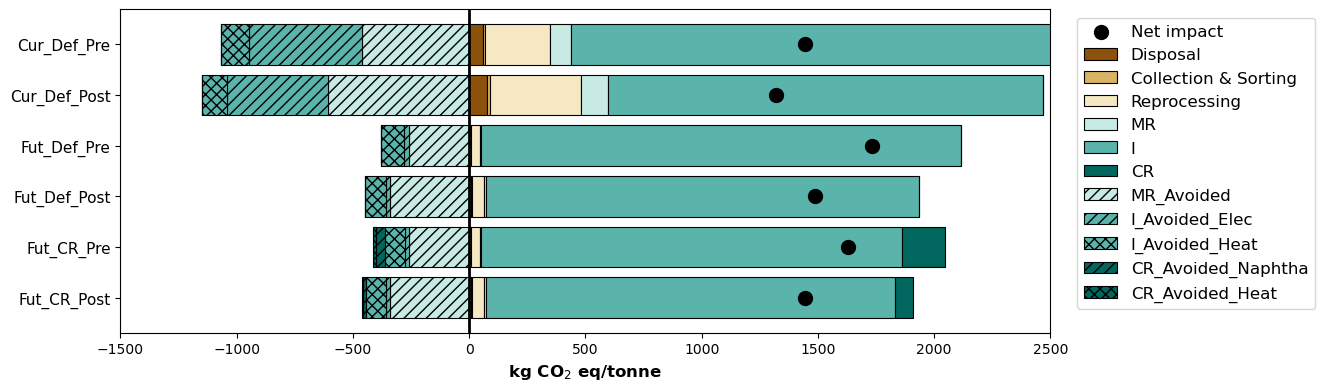

In [157]:
## Plotting env impact
process_order = [
    "Disposal",
    "Collection & Sorting",
    "Reprocessing",
    "MR",
    "I",
    "CR",
    "MR_Avoided",
    "I_Avoided_Elec",
    "I_Avoided_Heat",
    "CR_Avoided_Naphtha",
    "CR_Avoided_Heat"
]

scenario_order = [
    "Fut_CR_Post",
    "Fut_CR_Pre",
    "Fut_Def_Post",
    "Fut_Def_Pre",
    "Cur_Def_Post",
    "Cur_Def_Pre",
]

# Define custom colors for each process (hex codes)
process_colors = {
    "Disposal": "#8C510A",
    "Collection & Sorting": "#D8B365",
    "Reprocessing": "#F6E8C3",
    "MR": "#C7EAE5",
    "I": "#5AB4AC",
    "CR": "#01665E",
    "MR_Avoided": "#C7EAE5",
    "I_Avoided_Elec": "#5AB4AC",
    "I_Avoided_Heat": "#5AB4AC",
    "CR_Avoided_Naphtha": "#01665E",
    "CR_Avoided_Heat": "#01665E",
}

# Define hatch patterns for specific processes (None = solid fill)
process_hatches = {
    "Disposal": None,
    "Collection & Sorting": None,
    "Reprocessing": None,
    "MR": None,
    "I": None,       # Vertical lines
    "CR": None,      # Cross pattern
    "MR_Avoided": '///',
    "I_Avoided_Elec": '///',
    "I_Avoided_Heat": 'xxx',
    "CR_Avoided_Naphtha": '///',
    "CR_Avoided_Heat": 'xxx',
}

# copy model output in new df to manipluate outside of model
footprint_plot = all_scenario_impacts.copy()
footprint_plot = footprint_plot.reindex(index=scenario_order)
footprint_plot = footprint_plot.reindex(columns=process_order)

# create a series for the net impact
net_impacts = (
    netimpacts_df
    .set_index("Scenario")
    .reindex(scenario_order)["NetImpact"]
)

#create figure
fig, ax = plt.subplots(figsize=(12, max(4, 0.7 * len(footprint_plot))))

# Separate stacking to the right and left of zero
left_pos = pd.Series(0, index=footprint_plot.index, dtype=float)
left_neg = pd.Series(0, index=footprint_plot.index, dtype=float)

for col in footprint_plot.columns:
    vals = footprint_plot[col].astype(float)
        # Get color and hatch for this process
    color = process_colors.get(col, 'gray')  # Default to gray if not specified
    hatch = process_hatches.get(col, None)   # Default to solid if not specified

    if (vals < 0).any():
        ax.barh(
            footprint_plot.index, 
            vals, 
            left=left_neg, 
            label=col,
            color=color,
            hatch=hatch,
            edgecolor='black', # makes hatch lines visible
            linewidth=0.8) # border and hatch line thickness
        left_neg = left_neg + vals
    else:
        ax.barh(
            footprint_plot.index, 
            vals, 
            left=left_pos, 
            label=col,
            color=color,
            hatch=hatch,
            edgecolor='black',
            linewidth=0.8)
        left_pos = left_pos + vals

ax.scatter(
    net_impacts,
    footprint_plot.index,
    s=100,
    c="black",
    marker="o",
    zorder=10,
    label="Net impact"
)

# adjusting the look of the graph
ax.axvline(0, color="black", linewidth=2)
ax.set_xlabel("kg CO$_2$ eq/tonne", fontsize = 12, fontweight='bold')
ax.tick_params(axis='y', labelsize=11)
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize = 12)
ax.set_xlim(-1500, 2500)


# plt.tight_layout()

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f"GHG_footprint_scenarios_{timestamp}.png", dpi=300, bbox_inches="tight")
plt.show()


In [158]:
# TODO include param change of ratio plastic in msw to pmd

def apply_parameter_change(
        base_inputparameterspre,
        base_inputparameterspost,
        spec
):
    '''
    reading base_input pre and post from copy made of original input files outside of this function
    '''
    
    sens_pre = base_inputparameterspre.copy()
    sens_post = base_inputparameterspost.copy()

        # read the values from the sens input file
    table_name = spec["Table"]
    type_change = spec["Type_Change"]
    row_label = spec["Row"]
    col_label = spec["Column"]
    new_value = spec["Value"]

    # Select the right table
    if table_name == "input_parameters_pre":
        table = sens_pre
    elif table_name == "input_parameters_post":
        table = sens_post

# make a condition if whole column or just one cell changes
    if type_change == "column":
        table[col_label] = new_value
    elif type_change == "cell":
        table.loc[row_label, col_label] = new_value

    return sens_pre, sens_post
    

In [159]:
sens_file = pd.read_csv(r"C:\Users\Rrichie\OneDrive - Radboud Universiteit\Documenten\Python Scripts\param_sens_values_new_format.csv", index_col=0)

sens_input_versions_pre = {}
sens_input_versions_post = {}

for spec_name, spec in sens_file.iterrows ():
    # spec_name is the index label of the row (e.g. "fraction plastic pmd")
    sens_pre, sens_post = apply_parameter_change(
        base_inputparameterspre, 
        base_inputparameterspost,
        spec)

    sens_input_versions_pre[spec_name] = sens_pre
    sens_input_versions_post[spec_name] = sens_post

In [160]:
for name, df in sens_input_versions_pre.items():
    print("Spec:", name)
    print(df.head())

# print(sens_input_versions_post)
# print(sens_pre)
# print(base_inputparameterspre)
# print(sens_post)

Spec: fraction plastic msw post max
             f_plastic_res  f_plastic_pmd  f_plastic_types_res  \
PE                   0.108         0.5975               0.0734   
PP                   0.108         0.5975               0.1101   
PET bottles          0.108         0.5975               0.2167   
PET trays            0.108         0.5975               0.0655   
Films                0.108         0.5975               0.2802   

             f_plastic_types_pmd  moisture_res  post_sort_yield  \
PE                        0.0885          0.22                0   
PP                        0.1488          0.22                0   
PET bottles               0.0970          0.33                0   
PET trays                 0.1494          0.22                0   
Films                     0.1781          0.29                0   

             plastic_sort_yield  reproc_yield  substitution_ratio_MR  \
PE                         0.90          0.80                    0.7   
PP                  

In [163]:
# function to run the model and returns only the net impacts

def run_net_impacts(
    input_parameters_pre, 
    input_parameters_post,
    input_municipalities_pre,
    input_municipalities_post,
    env_impact_per_process_pre_current,
    env_impact_per_process_post_current,
    env_impact_per_process_pre_future,
    env_impact_per_process_post_future  
):
    _, netimpacts_df, _, _, _, _ = CH1_model(
    input_parameters_pre, 
    input_parameters_post,
    input_municipalities_pre,
    input_municipalities_post,
    env_impact_per_process_pre_current,
    env_impact_per_process_post_current,
    env_impact_per_process_pre_future,
    env_impact_per_process_post_future)

    return netimpacts_df


In [164]:
# running the sensitivity analyses
sens_results = []

for spec_name in sens_input_versions_pre.keys():
    sens_pre = sens_input_versions_pre[spec_name]
    sens_post = sens_input_versions_post[spec_name]

    netimpacts_df = run_net_impacts(
        sens_pre,
        sens_post,
        base_inputmunicipalitiespre,   # same municipalities for all specs
        base_inputmunicipalitiespost,
        env_impact_per_process_pre_current,
        env_impact_per_process_post_current,
        env_impact_per_process_pre_future,
        env_impact_per_process_post_future,
    )

    # add metadata columns
    netimpacts_df["SpecName"] = spec_name

    sens_results.append(netimpacts_df)

# combine all runs into one dataframe
all_sensitivity_netimpacts = pd.concat(sens_results, ignore_index=True)

In [166]:
netimpacts_df

,Scenario,NetImpact,SpecName
0,Cur_Def_Pre,1532.305011,substititution MR pre PP min
1,Cur_Def_Post,1320.990049,substititution MR pre PP min
2,Fut_Def_Pre,1795.144294,substititution MR pre PP min
3,Fut_Def_Post,1486.721087,substititution MR pre PP min
4,Fut_CR_Pre,1691.280482,substititution MR pre PP min
5,Fut_CR_Post,1443.898803,substititution MR pre PP min


In [165]:
print(all_sensitivity_netimpacts.head())

       Scenario    NetImpact                       SpecName
0   Cur_Def_Pre  1443.702594  fraction plastic msw post max
1  Cur_Def_Post  1320.990049  fraction plastic msw post max
2   Fut_Def_Pre  1733.899630  fraction plastic msw post max
3  Fut_Def_Post  1486.721087  fraction plastic msw post max
4    Fut_CR_Pre  1630.035818  fraction plastic msw post max


In [167]:
pivot = all_sensitivity_netimpacts.pivot(
    index="SpecName",
    columns="Scenario",
    values="NetImpact",
)

In [168]:
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
pivot.to_excel(f"netimpacts_sensitivity_{timestamp}.xlsx")

================================= If I just want to run the code once ================================================

In [70]:
### 1. Mass flow
plastic_types = ['PE', 'PP', 'PET bottles', 'PET trays', 'Films', 'Mixed']
# rescaling post-sorting Disposal

# 1.1 extract input parameters
M_collect_wet_post_res = input_municipalities_post["w_res"]
f_plastic_post_res = input_parameters_post["f_plastic_res"]
f_type_post_res = input_parameters_post["f_plastic_types_res"]
f_moisture_post_res = input_parameters_post["moisture_res"]
y_post_sort = input_parameters_post["post_sort_yield"]
y_plastic_sort = input_parameters_post["plastic_sort_yield"]
y_reproc = input_parameters_post["reproc_yield"]

# 1.2 Determine scaling factors
k_post = 1000 / sum(
    M_collect_wet_post_res *
    f_plastic_post_res[w] *
    f_type_post_res[w] *
    (1 - f_moisture_post_res[w])
    for w in plastic_types
    )
print(k_post)

# 1.3 Determine M_scaled_dry_post_res
# making sure it takes the first row ("municipality"). If I want to run another municipality I can simply add a row in excel file and change the index.
mun_post = input_municipalities_post.index[0]
# making a dataframe to be filled
M_scaled_dry_post_res = pd.DataFrame(
    index = plastic_types,
    columns = [mun_post],
    dtype = float
)

# calculating M_scaled_dry_post_res over plastic types

for w in plastic_types:
    M_scaled_dry_post_res.loc[w] = (
        M_collect_wet_post_res *
        f_plastic_post_res[w] *
        f_type_post_res[w] *
        (1 - f_moisture_post_res[w]) *
        k_post
    ) 





post    0.449129
Name: w_res, dtype: float64


In [71]:
### put the mass flows into a dataframe
post_processes = [
    "MSW Disposal",
    "Collection",
    "Post_sorting",
    "PMD_sorting",
    "Reprocessing",
    "MR",
    "I",
    "CR"
]

mass_flows_post = pd.DataFrame(
    index=plastic_types, 
    columns=post_processes, 
    dtype=float)

mass_flows_post["MSW Disposal"] = M_scaled_dry_post_res
mass_flows_post["Collection"] = M_scaled_dry_post_res
mass_flows_post["Post_sorting"] = M_scaled_dry_post_res
mass_flows_post["PMD_sorting"] = mass_flows_post["Post_sorting"] * y_post_sort
mass_flows_post["Reprocessing"] = mass_flows_post["PMD_sorting"] * y_plastic_sort
mass_flows_post["MR"] = mass_flows_post["Reprocessing"] * y_reproc
mass_flows_post["I"] = (
    mass_flows_post["Post_sorting"]*(1-y_post_sort) +
    mass_flows_post["PMD_sorting"]*(1-y_plastic_sort) +
    mass_flows_post["Reprocessing"]*(1-y_reproc)
    )

mass_flows_post.loc["Mixed", "I"] = mass_flows_post.loc["Mixed", "I"] + mass_flows_post.loc["Mixed", "MR"]
mass_flows_post.loc["Mixed", "MR"] = 0


print(mass_flows_post)


             MSW Disposal  Collection  Post_sorting  PMD_sorting  \
PE              77.011761   77.011761     77.011761    50.827762   
PP             115.366976  115.366976    115.366976    41.532111   
PET bottles    178.134746  178.134746    178.134746   126.475670   
PET trays       68.660570   68.660570     68.660570    41.882948   
Films          281.832019  281.832019    281.832019   140.916010   
Mixed          278.993928  278.993928    278.993928    83.698178   

             Reprocessing         MR           I  CR  
PE              45.744986  33.851290   43.160472 NaN  
PP              33.225689  22.593469   92.773508 NaN  
PET bottles    101.180536  62.731932  115.402814 NaN  
PET trays       35.600505  18.868268   49.792302 NaN  
Films           98.641207  44.388543  237.443476 NaN  
Mixed           37.664180   0.000000  278.993928 NaN  


In [72]:
### Bar chart material fractions
loss_post_barchart = [
    "MR",
    "I_post_sorting_loss",
    "I_PMD_sorting_loss",
    "I_reproc_loss",
]

loss_post_barchart = pd.DataFrame(
    index=plastic_types,
    columns=loss_post_barchart,
    dtype=float
)

loss_post_barchart["MR"] = mass_flows_post["MR"]
loss_post_barchart["I_post_sorting_loss"] = mass_flows_post["Post_sorting"]*(1-y_post_sort)
loss_post_barchart["I_PMD_sorting_loss"] = mass_flows_post["PMD_sorting"]*(1-y_plastic_sort)
loss_post_barchart["I_reproc_loss"] = mass_flows_post["Reprocessing"]*(1-y_reproc)
loss_post_barchart.loc["Mixed", "I_reproc_loss"] = mass_flows_post.loc["Mixed", "Reprocessing"]
print(loss_post_barchart)


                    MR  I_post_sorting_loss  I_PMD_sorting_loss  I_reproc_loss
PE           33.851290            26.183999            5.082776      11.893696
PP           22.593469            73.834865            8.306422      10.632221
PET bottles  62.731932            51.659076           25.295134      38.448604
PET trays    18.868268            26.777622            6.282442      16.732238
Films        44.388543           140.916010           42.274803      54.252664
Mixed         0.000000           195.295749           46.033998      37.664180


In [73]:
# post-sorting sankey

# Define all nodes (left to right)
label_list = [
    "Disposal",          # 0
    "Post-sorting",      # 1
    "PMD sorting",       # 2
    "Reprocessing",      # 3
    "Mechanical recycling",  # 4
    "WtE incineration"           # 5
]

# Define colors for each origin material
origin_colors = {
    "PE": "#ffffcc",      
    "PP": "#c7e9b4",    
    "PET bottles": "#7fcdbb",
    "PET trays": "#41b6c4",    
    "Films": "#2c7fb8",      
    "Mixed": "#253494" 
}

y_positions = [
    0.4,   # Disposal (centered)
    0.4,   # Post-sorting
    0.4,   # PMD sorting
    0.4,   # Reprocessing
    0.25,  # Mechanical recycling
    0.75,  # Incineration
]

# Define the flows with colors
# Each flow keeps its origin color throughout
source = [
    # From Disposal to post-sorting
    0, 0, 0, 0, 0, 0,  # PE, PP, PET bottles, PET trays, Films, Mixed -> Post-sorting
    
    # From post-sorting to PMD sorting & inc
    1, 1, 1, 1, 1, 1,   # Post-sorting -> PMD sorting (6 separate flows)
    1, 1, 1, 1, 1, 1,   # Post-sorting -> PMD sorting (6 separate flows)
    
    # From PMD sorting to Reprocessing & inc
    2, 2, 2, 2, 2, 2,  # PMD sorting -> Reprocessing (6 separate flows)
    2, 2, 2, 2, 2, 2,  # PMD sorting -> incineration (6 separate flows)
    
    # From Reprocessing to final destinations
    3, 3, 3, 3, 3,  # Reprocessing -> Mechanical recycling (6 flows)
    3, 3, 3, 3, 3, 3, # Reprocessing -> Incineration (6 flows)
]

target = [
    # To post-sorting
    1, 1, 1, 1, 1, 1,  # All inputs -> Post-sorting
    
    # from post to PMD sorting & inc
    2, 2, 2, 2, 2, 2,  # Post-sorting -> PMD sorting
    5, 5, 5, 5, 5, 5,  # To incineration
    
    # from PMD to Reprocessing & incineration
    3, 3, 3, 3, 3, 3,  # PMD sorting -> Reprocessing
    5, 5, 5, 5, 5, 5,  # To incineration
    
    # To final destinations (split between recycling and incineration)
    4, 4, 4, 4, 4,  # To mechanical recycling
    5, 5, 5, 5, 5, 5,  # To incineration
]

# Flow values - each origin material tracked separately
# Adjust these values based on your actual data
values = [
    # Inputs to post-sorting (original amounts)
    77,  # PE
    115,  # PP
    178,   # PET bottles
    69,   # PET trays
    282,  # Films
    279,   # Mixed
    
    # Post-sorting to PMD sorting (amounts after sorting losses)
    59,   # PE (95% of 100)
    89,  # PP (93% of 150)
    146,   # PET bottles
    58,   # PET trays
    197,  # Films
    89,   # Mixed

    # from post-sorting to incineration
    18,
    26,
    32,
    11,
    85,
    190,
    
    # PMD sorting to Reprocessing
    53,   # PE
    71,  # PP
    124,   # PET bottles
    50,   # PET trays
    168,  # Films
    45,   # Mixed

    # PMD sorting to incineration
    6,
    18,
    22,
    8,
    29,
    44,
    
    # Reprocessing to Mechanical recycling 
    43,   # PE 
    55,  # PP
    82,   # PET bottles
    31,   # PET trays
    114,   # Films

    
    # Reprocessing to Incineration 
    10,   # PE 
    16,   # PP
    42,   # PET bottles
    19,   # PET trays
    54,   # Films
    45,   # Mixed
]

# Create color list for each flow (maintains origin color throughout)
base_colors = [
    # Inputs to post-sorting
    origin_colors["PE"],
    origin_colors["PP"],
    origin_colors["PET bottles"],
    origin_colors["PET trays"],
    origin_colors["Films"],
    origin_colors["Mixed"],
] 
flow_colors = (
    base_colors * 5
    + [
    origin_colors["PE"],
    origin_colors["PP"],
    origin_colors["PET bottles"],
    origin_colors["PET trays"],
    origin_colors["Films"],
] + base_colors)

# Create the Sankey diagram
fig = go.Figure(go.Sankey(
    arrangement= "freeform",
    node=dict(
        pad=15,
        thickness=50,
        line=dict(color="black", width=0.5),
        # label=label_list,
        color="lightgray",  # Node color (neutral)
        x=[0.0, 0.25, 0.5, 0.75, 0.9, 0.9],
        y=y_positions,
        customdata=label_list,
        hovertemplate="<b>%{customdata}</b><extra></extra>"
    ),
    link=dict(
        source=source,
        target=target,
        value=values,
        color=flow_colors,  # Each flow keeps its origin color
        line=dict(color="black", width=0.5)
    )
))

for material, color in origin_colors.items():
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(
                size=12,
                color=color
            ),
            name=material,
            showlegend=True,
            hoverinfo="skip"
        )
    )


# Update layout
fig.update_layout(
    title_text="Post-sorted Plastic Waste Flow - Material Tracking",
    font=dict(size=16, family="Arial", color="black"),
    width=1200,
    height=700,
    paper_bgcolor="white",
    plot_bgcolor= "white",
    margin=dict(l=20, r=20, t=60, b=20),
    legend=dict(
        title=dict(text="PPW types"),
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top",
        font=dict(size=14)
    )
)

fig.update_xaxes(
    visible=False,
    showgrid=False,
    zeroline=False,
    showticklabels=False
)

fig.update_yaxes(
    visible=False,
    showgrid=False,
    zeroline=False,
    showticklabels=False
)

# Show interactive plot
fig.show()

# # Save outputs
# fig.write_html("plastic_waste_sankey_tracked.html")
# fig.write_image("plastic_waste_sankey_tracked.png", width=1200, height=700, scale=2)

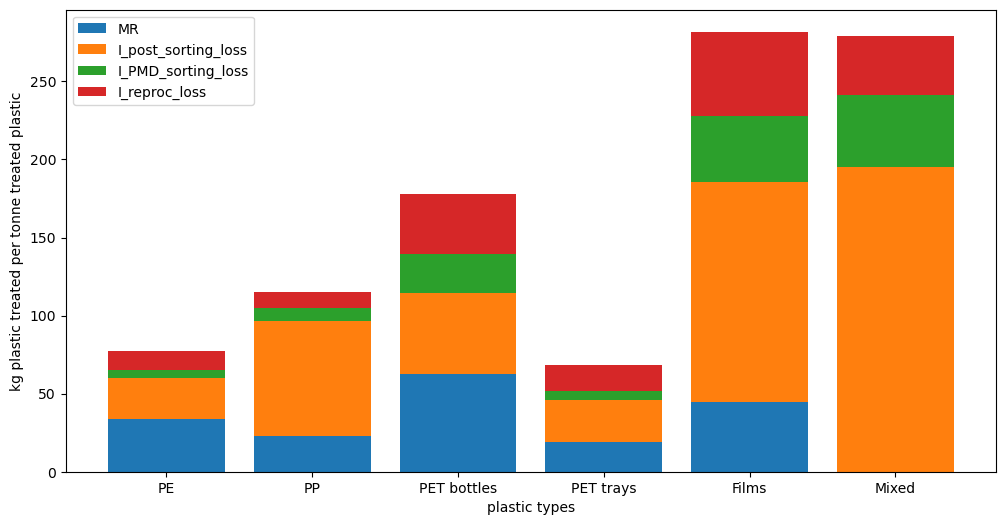

In [74]:
### Creating post barchart figure
fig, ax = plt.subplots(figsize=(12,6))

bottom = np.zeros(len(plastic_types))
ax.bar(plastic_types, loss_post_barchart["MR"], label = "MR", bottom=bottom)
bottom += loss_post_barchart["MR"]
ax.bar(plastic_types, loss_post_barchart["I_post_sorting_loss"], label = "I_post_sorting_loss", bottom=bottom)
bottom += loss_post_barchart["I_post_sorting_loss"]
ax.bar(plastic_types, loss_post_barchart["I_PMD_sorting_loss"], label = "I_PMD_sorting_loss", bottom=bottom)
bottom += loss_post_barchart["I_PMD_sorting_loss"]
ax.bar(plastic_types, loss_post_barchart["I_reproc_loss"], label = "I_reproc_loss", bottom=bottom)
plt.xlabel('plastic types')
plt.ylabel('kg plastic treated per tonne treated plastic')
ax.legend(loc='upper left')

#create timstamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'losses_barchart_post_{timestamp}.png', dpi=300, bbox_inches='tight')
plt.show()

18.243350146830196
81.7566498531698
81.7566498531698


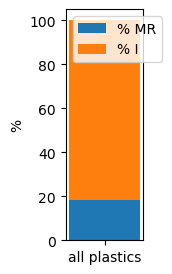

In [75]:
### Creating post recycling percentage figure

total_post_MR = loss_post_barchart["MR"].sum()
total_post_I = mass_flows_post["I"].sum()

perct_MR = (total_post_MR / 1000)*100
Perct_I = 100-perct_MR
perct_I = (total_post_I/1000)*100
print(perct_MR)
print(Perct_I)
print(perct_I)

fig, ax = plt.subplots(figsize=(1,3))
ax.bar('all plastics', perct_MR, label = "% MR")
ax.bar('all plastics', perct_I, bottom=perct_MR, label = "% I")
ax.legend(loc='upper left')
plt.ylabel("%")

#create timstamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'recycling_percentage_post{timestamp}.png', bbox_inches='tight')
plt.show()


In [76]:
# Pre-sorting
# 1.1 extract input parameters
M_collect_wet_pre_res = input_municipalities_pre["w_res"]
M_collect_wet_pmd = input_municipalities_pre["w_pmd"]
# print(M_collect_wet_post_res)
f_plastic_pre_res = input_parameters_pre["f_plastic_res"]
f_plastic_pre_pmd = input_parameters_pre["f_plastic_pmd"]
f_type_pre_res = input_parameters_pre["f_plastic_types_res"]
f_type_pre_pmd = input_parameters_pre["f_plastic_types_pmd"]
f_moisture_pre_res = input_parameters_pre["moisture_res"]
y_plastic_sort = input_parameters_pre["plastic_sort_yield"]
y_reproc = input_parameters_pre["reproc_yield"]


# 1.2 Determine scaling factors
k_pre = 1000 / sum(
    M_collect_wet_pre_res *
    f_plastic_pre_res[w] *
    f_type_pre_res[w] *
    (1 - f_moisture_pre_res[w]) +
    M_collect_wet_pmd *
    f_plastic_pre_pmd[w] *
    f_type_pre_pmd[w]
    for w in plastic_types
    )

print(k_pre)

# 1.3 Determine M_scaled_dry_pre_res
# making sure it takes the first row ("municipality"). If I want to run another municipality I can simply add a row in excel file and change the index.
mun_pre = input_municipalities_pre.index[0]
# making a dataframe to be filled
M_scaled_dry_pre_res = pd.DataFrame(
    index = plastic_types,
    columns = [mun_pre],
    dtype = float
)

# calculating M_scaled_dry_pre_res over plastic types

for w in plastic_types:
    M_scaled_dry_pre_res.loc[w] = (
        M_collect_wet_pre_res *
        f_plastic_pre_res[w] *
        f_type_pre_res[w] *
        (1 - f_moisture_pre_res[w]) *
        k_pre
    ) 
print(M_scaled_dry_pre_res)

# 1.4 Determine M_scaled_dry_pre_pmd
# making a dataframe to be filled
M_scaled_dry_pre_pmd = pd.DataFrame(
    index = plastic_types,
    columns = [mun_pre],
    dtype = float
)

# calculating M_scaled_dry_pre_pmd over plastic types

for w in plastic_types:
    M_scaled_dry_pre_pmd.loc[w] = (
        M_collect_wet_pmd *
        f_plastic_pre_pmd[w] *
        f_type_pre_pmd[w] *
        k_pre
        ) 
print(M_scaled_dry_pre_pmd)



pre    0.376128
dtype: float64
                   pre
PE           28.452346
PP           42.678519
PET bottles  72.154120
PET trays    25.390036
Films        98.867579
Mixed        92.183872
                    pre
PE            56.664207
PP            95.272701
PET bottles   62.106532
PET trays     95.656865
Films        114.032715
Mixed        216.540507


In [ ]:
print(M_scaled_dry_pre_pmd)

In [77]:
### put the mass flows into a dataframe
pre_processes = [
    "MSW Disposal",
    "PMD Disposal",
    "PMD_sorting",
    "Collection",
    "Reprocessing",
    "MR",
    "I",
    "CR"
]



mass_flows_pre = pd.DataFrame(
    index=plastic_types,
    columns=pre_processes,
    dtype=float
    )

mass_flows_pre["MSW Disposal"] = M_scaled_dry_pre_res
mass_flows_pre["PMD Disposal"] = M_scaled_dry_pre_pmd
mass_flows_pre["Collection"] = M_scaled_dry_pre_res + M_scaled_dry_pre_pmd
mass_flows_pre["PMD_sorting"] = M_scaled_dry_pre_pmd
mass_flows_pre["Reprocessing"] = mass_flows_pre["PMD_sorting"] * y_plastic_sort
mass_flows_pre["MR"] = mass_flows_pre["Reprocessing"] * y_reproc
mass_flows_pre["I"] = (
    M_scaled_dry_pre_res.squeeze() +
    mass_flows_pre["PMD_sorting"]*(1-y_plastic_sort) +
    mass_flows_pre["Reprocessing"]*(1-y_reproc)
    )

mass_flows_pre.loc["Mixed", "I"] = mass_flows_pre.loc["Mixed", "I"] + mass_flows_pre.loc["Mixed", "MR"]
mass_flows_pre.loc["Mixed", "MR"] = 0

print(mass_flows_pre)

             MSW Disposal  PMD Disposal  PMD_sorting  Collection  \
PE              28.452346     56.664207    56.664207   85.116553   
PP              42.678519     95.272701    95.272701  137.951220   
PET bottles     72.154120     62.106532    62.106532  134.260652   
PET trays       25.390036     95.656865    95.656865  121.046901   
Films           98.867579    114.032715   114.032715  212.900294   
Mixed           92.183872    216.540507   216.540507  308.724379   

             Reprocessing         MR           I  CR  
PE              50.997787  37.738362   47.378191 NaN  
PP              76.218161  51.828349   86.122871 NaN  
PET bottles     49.685226  30.804840  103.455812 NaN  
PET trays       81.308335  43.093418   77.953484 NaN  
Films           79.822901  35.920305  176.979989 NaN  
Mixed           97.443228   0.000000  308.724379 NaN  


In [78]:
plastic_res = mass_flows_pre["MSW Disposal"].sum()
plastic_pmd = mass_flows_pre["PMD Disposal"].sum()
perct_in_pmd = plastic_pmd/(plastic_pmd + plastic_res)
print (perct_in_pmd)

0.6402735282094988


In [79]:
# Pre-sorting

# Define all nodes (left to right)
label_list = [
    "PMD Disposal",              #0
    "MSW Disposal",              #1
    
    # Middle 
    "PMD sorting",          #2
    "Reprocessing",         #3
    
    # Right side - Final destinations (2)
    "Mechanical recycling", #4
    "Incineration"          #5
]

# Define colors for each origin material
origin_colors = {
    "PE": "#ffffcc",      
    "PP": "#c7e9b4",    
    "PET bottles": "#7fcdbb",
    "PET trays": "#41b6c4",    
    "Films": "#2c7fb8",      
    "Mixed": "#253494" 
}

y_positions = [
    0.4,   # Disposal 
    0.9,   # Disposal
    0.4,   # PMD sorting
    0.4,   # Reprocessing
    0.25,  # Mechanical recycling
    0.75,  # Incineration
]

# Define the flows with colors
# Each flow keeps its origin color throughout
source = [
    # From inputs to pmd-sorting and inc
    0, 0, 0, 0, 0, 0, # PMD: PE, PP, PET bottles, PET trays, Films, Mixed -> PMD-sorting
    1, 1, 1, 1, 1, 1, # MSW: PE, PP, PET bottles, PET trays, Films, Mixed -> inc
    
    # From PMD sorting to Reprocessing & inc
    2, 2, 2, 2, 2, 2,  # PMD -> reproc
    2, 2, 2, 2, 2, 2, # PMD -> inc
    
    # From Reprocessing to final destinations
    3, 3, 3, 3, 3, 3, # Reprocessing -> Mechanical recycling (6 flows)
    3, 3, 3, 3, 3, 3,  # Reprocessing -> Incineration (6 flows)
]

target = [
    # To pMD-sorting
    2, 2, 2, 2, 2, 2,  # PMD -> PMD-sorting
    5, 5, 5, 5, 5, 5,  # MSW -> incineration
    
    # from PMD to Reprocessing & incineration
    3, 3, 3, 3, 3, 3,  # PMD sorting -> Reprocessing
    5, 5, 5, 5, 5, 5,  # To incineration
    
    # To final destinations (split between recycling and incineration)
    4, 4, 4, 4, 4, 4,  # To mechanical recycling
    5, 5, 5, 5, 5, 5,  # To incineration
]

# Flow values - each origin material tracked separately
# Adjust these values based on your actual data
values = [
    # PMD to PMD sorting
    57,  # PE
    95,  # PP
    62,   # PET bottles
    96,   # PET trays
    114,  # Films
    217,   # Mixed

    # MSW to inc
    28,     # PE to inc
    43,  # PP (93% of 150)
    72,   # PET bottles
    26,   # PET trays
    99,  # Films
    92,   # Mixed

    # PMD sorting to Reprocessing
    51,   # PE
    76,  # PP
    53,   # PET bottles
    81,   # PET trays
    97,  # Films
    108,   # Mixed

    # PMD sorting to incineration
    6,
    19,
    9,
    15,
    17,
    109,
    
    # Reprocessing to Mechanical recycling 
    41,   # PE 
    59,  # PP
    35,   # PET bottles
    50,   # PET trays
    66,   # Films
    0,   # Mixed
    
    # Reprocessing to Incineration 
    10,   # PE 
    17,   # PP
    18,   # PET bottles
    31,   # PET trays
    31,   # Films
    108,   # Mixed
]

# Create color list for each flow (maintains origin color throughout)
flow_colors = [
    # Inputs to post-sorting
    origin_colors["PE"],
    origin_colors["PP"],
    origin_colors["PET bottles"],
    origin_colors["PET trays"],
    origin_colors["Films"],
    origin_colors["Mixed"],
] *6

# Create the Sankey diagram
fig = go.Figure(go.Sankey(
    arrangement= "freeform",
    node=dict(
        pad=15,
        thickness=50,
        line=dict(color="black", width=0.5),
        # label=label_list,
        color="lightgray",  # Node color (neutral)
        x=[0, 0,
           0.5, 0.75,    # Middle nodes
           0.9, 0.9],         # Right side outputs
        y=y_positions
    ),
    link=dict(
        source=source,
        target=target,
        value=values,
        color=flow_colors,  # Each flow keeps its origin color
        line=dict(color="black", width=0.5)  # Optional: add borders to flows
    )
))

for material, color in origin_colors.items():
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(
                size=12,
                color=color
            ),
            name=material,
            showlegend=True,
            hoverinfo="skip"
        )
    )


# Update layout
fig.update_layout(
    title_text="Pre-sorted Plastic Waste Flow - Material Tracking",
    font=dict(size=16, family="Arial", color="black"),
    width=1200,
    height=700,
    paper_bgcolor="white",
    plot_bgcolor= "white",
    margin=dict(l=20, r=20, t=60, b=20),
    legend=dict(
        title=dict(text="PPW types"),
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top",
        font=dict(size=14)
    )
)

fig.update_xaxes(
    visible=False,
    showgrid=False,
    zeroline=False,
    showticklabels=False
)

fig.update_yaxes(
    visible=False,
    showgrid=False,
    zeroline=False,
    showticklabels=False
)

# Show interactive plot
fig.show()

In [80]:
netimpacts_df

,Scenario,NetImpact
0,Cur_Def_Pre,1599.952529
1,Cur_Def_Post,1685.460891
2,Fut_Def_Pre,1924.011918
3,Fut_Def_Post,2004.459601
4,Fut_CR_Pre,1830.534488
5,Fut_CR_Post,1968.328299


In [81]:
### Bar chart material fractions
loss_pre_barchart = [
    "MR",
    "I_MSW_Disposal",
    "I_PMD_sorting_loss",
    "I_reproc_loss",
]

loss_pre_barchart = pd.DataFrame(
    index=plastic_types,
    columns=loss_pre_barchart,
    dtype=float
)

loss_pre_barchart["MR"] = mass_flows_pre["MR"]
loss_pre_barchart["I_MSW_Disposal"] = M_scaled_dry_pre_res
loss_pre_barchart["I_PMD_sorting_loss"] = mass_flows_pre["PMD_sorting"]*(1-y_plastic_sort)
loss_pre_barchart["I_reproc_loss"] = mass_flows_pre["Reprocessing"]*(1-y_reproc)
loss_pre_barchart.loc["Mixed", "I_reproc_loss"] = mass_flows_pre.loc["Mixed", "Reprocessing"]
print(loss_pre_barchart)

                    MR  I_MSW_Disposal  I_PMD_sorting_loss  I_reproc_loss
PE           37.738362       28.452346            5.666421      13.259424
PP           51.828349       42.678519           19.054540      24.389811
PET bottles  30.804840       72.154120           12.421306      18.880386
PET trays    43.093418       25.390036           14.348530      38.214918
Films        35.920305       98.867579           34.209815      43.902595
Mixed         0.000000       92.183872          119.097279      97.443228


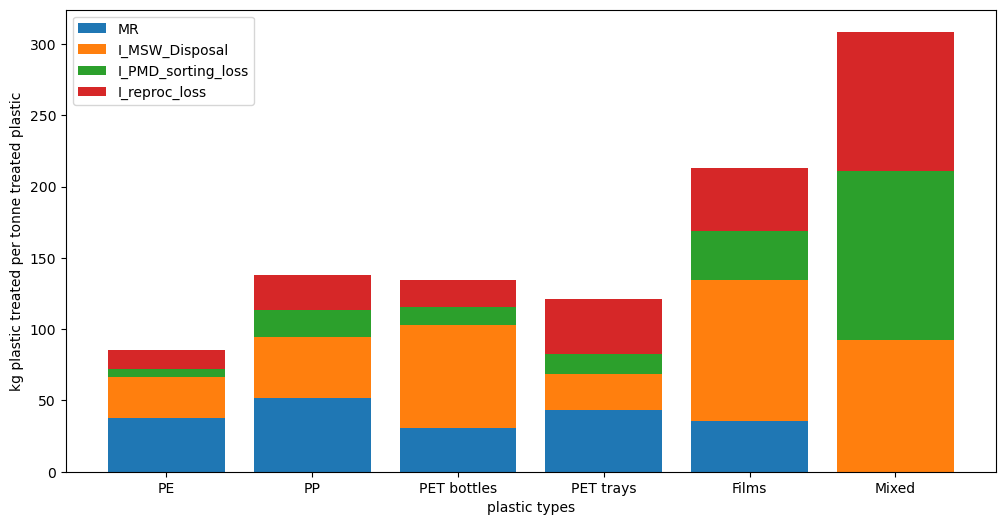

In [82]:
### Creating pre barchart figure
fig, ax = plt.subplots(figsize=(12,6))

bottom = np.zeros(len(plastic_types))
ax.bar(plastic_types, loss_pre_barchart["MR"], label = "MR", bottom=bottom)
bottom += loss_pre_barchart["MR"]
ax.bar(plastic_types, loss_pre_barchart["I_MSW_Disposal"], label = "I_MSW_Disposal", bottom=bottom)
bottom += loss_pre_barchart["I_MSW_Disposal"]
ax.bar(plastic_types, loss_pre_barchart["I_PMD_sorting_loss"], label = "I_PMD_sorting_loss", bottom=bottom)
bottom += loss_pre_barchart["I_PMD_sorting_loss"]
ax.bar(plastic_types, loss_pre_barchart["I_reproc_loss"], label = "I_reproc_loss", bottom=bottom)
plt.xlabel('plastic types')
plt.ylabel('kg plastic treated per tonne treated plastic')
ax.legend(loc='upper left')

#create timstamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'losses_barchart_pre_{timestamp}.png', dpi=300, bbox_inches='tight')
plt.show()

19.938527443501847
80.06147255649816


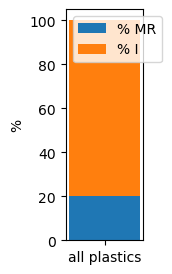

In [83]:
### Creating pre recycling percentage figure

total_pre_MR = loss_pre_barchart["MR"].sum()
total_pre_I = mass_flows_pre["I"].sum()

perct_MR = (total_pre_MR / 1000)*100
perct_I = (total_pre_I/1000)*100
print(perct_MR)
print(perct_I)
fig, ax = plt.subplots(figsize=(1,3))
ax.bar('all plastics', perct_MR, label = "% MR")
ax.bar('all plastics', perct_I, bottom=perct_MR, label = "% I")
ax.legend(loc='upper left')
plt.ylabel("%")

#create timstamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'recycling_percentage_pre_{timestamp}.png', bbox_inches='tight')
plt.show()

In [11]:
print(mass_flows_post_all)
print(mass_flows_post_all_CR)

             MSW Disposal  Collection  Post_sorting  PMD_sorting  \
PE              77.011761   77.011761     77.011761    59.299056   
PP             115.366976  115.366976    115.366976    88.832572   
PET bottles    178.134746  178.134746    178.134746   146.070492   
PET trays       68.660570   68.660570     68.660570    58.361484   
Films          281.832019  281.832019    281.832019   197.282413   
Mixed          278.993928  278.993928    278.993928    89.278057   

             Reprocessing          MR           I  CR  MR_Avoided   I_Avoided  
PE              53.369151   48.032236   28.979526 NaN  -33.622565  -23.183621  
PP              71.066057   60.406149   54.960827 NaN  -42.284304  -43.968662  
PET bottles    124.159918   93.119938   85.014808 NaN  -83.807945  -68.011846  
PET trays       49.607262   34.725083   33.935487 NaN  -24.307558  -27.148389  
Films          167.690051  134.152041  147.679978 NaN  -67.076021 -118.143982  
Mixed           44.639028   35.711223  243.

In [52]:
### Calculated avoided mass streams
# import substitution ratios
substitution_ratio_MR_post = input_parameters_post["substitution_ratio_MR"]
substitution_ratio_I_Elec_post = input_parameters_post["substitution_ratio_I_Elec"]
substitution_ratio_I_Heat_post = input_parameters_post["substitution_ratio_I_Heat"]
substitution_ratio_CR_Naphtha_post = input_parameters_post["substitution_ratio_CR_Naphtha"]
substitution_ratio_CR_Heat_post = input_parameters_post["substitution_ratio_CR_Heat"]
substitution_ratio_MR_pre = input_parameters_pre["substitution_ratio_MR"]
substitution_ratio_I_Elec_pre = input_parameters_pre["substitution_ratio_I_Elec"]
substitution_ratio_I_Heat_pre = input_parameters_pre["substitution_ratio_I_Heat"]
substitution_ratio_CR_Naphtha_pre = input_parameters_pre["substitution_ratio_CR_Naphtha"]
substitution_ratio_CR_Heat_pre = input_parameters_pre["substitution_ratio_CR_Heat"]
# print(mass_flows_post)

mass_flows_post_all = mass_flows_post.copy()
mass_flows_post_all["MR_Avoided"] = -mass_flows_post_all["MR"] * substitution_ratio_MR_post
# TODO subtract with LDPE needed for bags
# 2.96 kg LDPE
# we put the same mass that is I in the avoided mass flow for elec and heat replacement 
# and apply a substitution ratio to convert to kWh and MJ so we can multiply with respective GHG footprints later
mass_flows_post_all["I_Avoided_Elec"] = -mass_flows_post_all["I"] * substitution_ratio_I_Elec_post
mass_flows_post_all["I_Avoided_Heat"] = -mass_flows_post_all["I"] * substitution_ratio_I_Heat_post

# print(mass_flows_post_all)

mass_flows_pre_all = mass_flows_pre.copy()
mass_flows_pre_all["MR_Avoided"] = -mass_flows_pre_all["MR"] * substitution_ratio_MR_pre
# TODO subtract with LDPE needed for bags
# 0.00296 * mass_scaled_msw + 0.00197 * mass_scaled_pmd
mass_flows_pre_all["I_Avoided_Elec"] = -mass_flows_pre_all["I"] * substitution_ratio_I_Elec_pre
mass_flows_pre_all["I_Avoided_Heat"] = -mass_flows_pre_all["I"] * substitution_ratio_I_Heat_pre
# print(mass_flows_pre_all)

# Adapting mass flows for CR scenarios
# pre
mass_flows_pre_all_CR = mass_flows_pre_all.copy()
# the mass that gets CR is what is incinerated expect for what was disposed in MSW
mass_flows_pre_all_CR["CR"] = (mass_flows_pre_all["I"] - mass_flows_pre["MSW Disposal"])
# we put the same mass that is CR in the avoided mass flow for naphtha and heat replacement 
# and apply a substitution ratio to convert to kg naphtha and MJ so we can multiply with respective GHG footprints later
mass_flows_pre_all_CR["CR_Avoided_Naphtha"] = -(mass_flows_pre_all["I"] - mass_flows_pre["MSW Disposal"]) * substitution_ratio_CR_Naphtha_pre
mass_flows_pre_all_CR["CR_Avoided_Heat"] = -(mass_flows_pre_all["I"] - mass_flows_pre["MSW Disposal"]) * substitution_ratio_CR_Heat_pre
# what was disposed in MSW bag is still incinerated
mass_flows_pre_all_CR["I"] = mass_flows_pre["MSW Disposal"]
mass_flows_pre_all_CR["I_Avoided_Elec"] = -mass_flows_pre["MSW Disposal"] * substitution_ratio_I_Elec_pre
mass_flows_pre_all_CR["I_Avoided_Heat"] = -mass_flows_pre["MSW Disposal"] * substitution_ratio_I_Heat_pre

# post
mass_flows_post_all_CR = mass_flows_post_all.copy()
mass_flows_post_all_CR["CR"] = mass_flows_post_all["I"]
mass_flows_post_all_CR["CR_Avoided_Naphtha"] = -mass_flows_post_all["I"] * substitution_ratio_CR_Naphtha_post
mass_flows_post_all_CR["CR_Avoided_Heat"] = -mass_flows_post_all["I"] * substitution_ratio_CR_Heat_post
mass_flows_post_all_CR["I"] = 0
mass_flows_post_all_CR["I_Avoided_Elec"] = 0
mass_flows_post_all_CR["I_Avoided_Heat"] = 0

In [57]:
# print(mass_flows_pre_all["I"])
# print(mass_flows_pre["MSW Disposal"])
print(mass_flows_pre_all_CR["I_Avoided_Elec"])

PE            -32.984967
PP            -41.324916
PET bottles   -75.093703
PET trays     -26.424435
Films         -97.034342
Mixed         -84.402448
Name: I_Avoided_Elec, dtype: float64


In [54]:
# print(env_impact_per_process_pre_current)
print(mass_flows_pre_all_CR)
print(mass_flows_post_all_CR)
# print(mass_flows_post_all)
# print(mass_flows_pre_all)
# print(substitution_ratio_I_pre)

             MSW Disposal  PMD Disposal  PMD_sorting  Collection  \
PE              18.741458     67.529878    67.529878   86.271336   
PP              28.112187    113.541760   113.541760  141.653948   
PET bottles     47.527660     74.015798    74.015798  121.543458   
PET trays       16.724326    113.999590   113.999590  130.723916   
Films           65.123720    135.899109   135.899109  201.022829   
Mixed           60.721186    258.063328   258.063328  318.784514   

             Reprocessing          MR          I          CR  MR_Avoided  \
PE              60.776890   54.699201  18.741458   12.830677  -38.289441   
PP              90.833408   77.208397  28.112187   36.333363  -54.045878   
PET bottles     62.913428   47.185071  47.527660   26.830727  -42.466564   
PET trays       96.899651   67.829756  16.724326   46.169834  -47.480829   
Films          115.514243   92.411394  65.123720   43.487715  -46.205697   
Mixed          129.031664  103.225331  60.721186  154.837997   -0.0

In [53]:
### Impact calculations

# calculating env impact per process corrected for kg treated by process
# TODO adapt env impact to include npatha, and heat
env_impact_corrected_Pre_Cur_Def = mass_flows_pre_all * env_impact_per_process_pre_current
env_impact_corrected_Post_Cur_Def = mass_flows_post_all * env_impact_per_process_post_current
env_impact_corrected_Pre_Fut_Def = mass_flows_pre_all * env_impact_per_process_pre_future
env_impact_corrected_Post_Fut_Def = mass_flows_post_all * env_impact_per_process_post_future
env_impact_corrected_Pre_Fut_CR = mass_flows_pre_all_CR * env_impact_per_process_pre_future
env_impact_corrected_Post_Fut_CR = mass_flows_post_all_CR * env_impact_per_process_post_future



# summing all plastics to one total impact per process
total_impact_Pre_Cur_Def = env_impact_corrected_Pre_Cur_Def.sum(axis=0).to_frame(name="Pre_Cur_Def")
total_impact_Post_Cur_Def = env_impact_corrected_Post_Cur_Def.sum(axis=0).to_frame(name="Post_Cur_Def")
total_impact_Pre_Fut_Def = env_impact_corrected_Pre_Fut_Def.sum(axis=0).to_frame(name="Pre_Fut_Def")
total_impact_Post_Fut_Def = env_impact_corrected_Post_Fut_Def.sum(axis=0).to_frame(name="Post_Fut_Def") 
total_impact_Pre_Fut_CR = env_impact_corrected_Pre_Fut_CR.sum(axis=0).to_frame(name="Pre_Fut_CR")
total_impact_Post_Fut_CR = env_impact_corrected_Post_Fut_CR.sum(axis=0).to_frame(name="Post_Fut_CR")



In [ ]:
# print(env_impact_per_process_pre_current)
print(mass_flows_pre_all)
print(mass_flows_post_all)
print(env_impact_corrected_Pre_Fut_Def)
print(env_impact_corrected_Post_Fut_Def)
# print(total_impact_Pre_Cur_Def)
# print(total_impact_Post_Cur_Def)
# print(total_impact_Pre_Fut_Def)
# print(total_impact_Post_Fut_Def)
# print(type(total_impact_Pre_Cur_Def))

In [54]:

# Rerun previous two cells to reset
# TODO collection and sorting samenvoegen
# re-indexing Pre_Cur_Def
total_impact_Pre_Cur_Def.loc["Disposal"] = total_impact_Pre_Cur_Def.loc["MSW Disposal"] + total_impact_Pre_Cur_Def.loc["PMD Disposal"]
total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["MSW Disposal"])
total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["PMD Disposal"])
total_impact_Pre_Cur_Def.loc["Sorting"] = total_impact_Pre_Cur_Def.loc["PMD_sorting"]
total_impact_Pre_Cur_Def = total_impact_Pre_Cur_Def.drop(index=["PMD_sorting"])

# re-indexing Post_Cur_Def
total_impact_Post_Cur_Def.loc["Disposal"] = total_impact_Post_Cur_Def.loc["MSW Disposal"]
total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["MSW Disposal"])
total_impact_Post_Cur_Def.loc["Sorting"] = total_impact_Post_Cur_Def.loc["PMD_sorting"] + total_impact_Post_Cur_Def.loc["Post_sorting"]
total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["PMD_sorting"])
total_impact_Post_Cur_Def = total_impact_Post_Cur_Def.drop(index=["Post_sorting"])

# re-indexing Pre_Fut_Def
total_impact_Pre_Fut_Def.loc["Disposal"] = total_impact_Pre_Fut_Def.loc["MSW Disposal"] + total_impact_Pre_Fut_Def.loc["PMD Disposal"]
total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["MSW Disposal"])
total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["PMD Disposal"])
total_impact_Pre_Fut_Def.loc["Sorting"] = total_impact_Pre_Fut_Def.loc["PMD_sorting"]
total_impact_Pre_Fut_Def = total_impact_Pre_Fut_Def.drop(index=["PMD_sorting"])

# re-indexing Post_Fut_Def
total_impact_Post_Fut_Def.loc["Disposal"] = total_impact_Post_Fut_Def.loc["MSW Disposal"]
total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["MSW Disposal"])
total_impact_Post_Fut_Def.loc["Sorting"] = total_impact_Post_Fut_Def.loc["PMD_sorting"] + total_impact_Post_Fut_Def.loc["Post_sorting"]
total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["PMD_sorting"])
total_impact_Post_Fut_Def = total_impact_Post_Fut_Def.drop(index=["Post_sorting"])

# re-indexing Pre_Fut_CR
total_impact_Pre_Fut_CR.loc["Disposal"] = total_impact_Pre_Fut_CR.loc["MSW Disposal"] + total_impact_Pre_Fut_CR.loc["PMD Disposal"]
total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["MSW Disposal"])
total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["PMD Disposal"])
total_impact_Pre_Fut_CR.loc["Sorting"] = total_impact_Pre_Fut_CR.loc["PMD_sorting"]
total_impact_Pre_Fut_CR = total_impact_Pre_Fut_CR.drop(index=["PMD_sorting"])

# re-indexing Post_Fut_CR
total_impact_Post_Fut_CR.loc["Disposal"] = total_impact_Post_Fut_CR.loc["MSW Disposal"]
total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["MSW Disposal"])
total_impact_Post_Fut_CR.loc["Sorting"] = total_impact_Post_Fut_CR.loc["PMD_sorting"] + total_impact_Post_Fut_CR.loc["Post_sorting"]
total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["PMD_sorting"])
total_impact_Post_Fut_CR = total_impact_Post_Fut_CR.drop(index=["Post_sorting"])

In [ ]:
# print(env_impact_corrected_Pre_Cur_Def)
# print(env_impact_corrected_Post_Cur_Def)
# print(env_impact_corrected_Pre_Fut_Def)
# print(env_impact_corrected_Post_Fut_Def)
# print(mass_flows_pre_all_CR)

print(total_impact_Pre_Cur_Def)
print(total_impact_Pre_Fut_CR)

In [55]:
### Creating one dataframe for all the scenarios
# defining results in to dictionary. Makes it easier to add scenarios later


scenario_results = {
    "Pre_Cur_Def": total_impact_Pre_Cur_Def["Pre_Cur_Def"],
    "Post_Cur_Def": total_impact_Post_Cur_Def["Post_Cur_Def"],
    "Pre_Fut_Def": total_impact_Pre_Fut_Def["Pre_Fut_Def"],
    "Post_Fut_Def": total_impact_Post_Fut_Def["Post_Fut_Def"],
    "Pre_Fut_CR": total_impact_Pre_Fut_CR["Pre_Fut_CR"],
    "Post_Fut_CR": total_impact_Post_Fut_CR["Post_Fut_CR"]
}

all_scenario_impacts = pd.DataFrame(scenario_results).T
print(all_scenario_impacts.to_string())
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
all_scenario_impacts.to_excel(f'impacts_{timestamp}.xlsx', index=False)

                       CR  CR_Avoided_Heat  CR_Avoided_Naphtha  Collection   Disposal            I  I_Avoided_Elec  I_Avoided_Heat          MR  MR_Avoided  Reprocessing    Sorting
Pre_Cur_Def      0.000000         0.000000            0.000000       2.564  50.478305  1328.132371     -310.888711      -76.558840  138.900717 -711.038087    428.530605   7.218450
Post_Cur_Def     0.000000         0.000000            0.000000       2.564  75.080000  1788.504837     -413.189442     -101.791743  117.000446 -606.337434    389.250524  12.039366
Pre_Fut_Def      0.000000         0.000000            0.000000       1.263   5.600863  1321.057068      -13.214546      -64.426390   10.783252 -398.814858     54.429440   2.351770
Post_Fut_Def     0.000000         0.000000            0.000000       1.263   8.331000  1779.310353      -17.562911      -85.660578    9.083568 -340.193977     49.475417   3.922424
Pre_Fut_CR     798.791796       -62.081867         -161.172567       1.263   5.600863    49.336802  

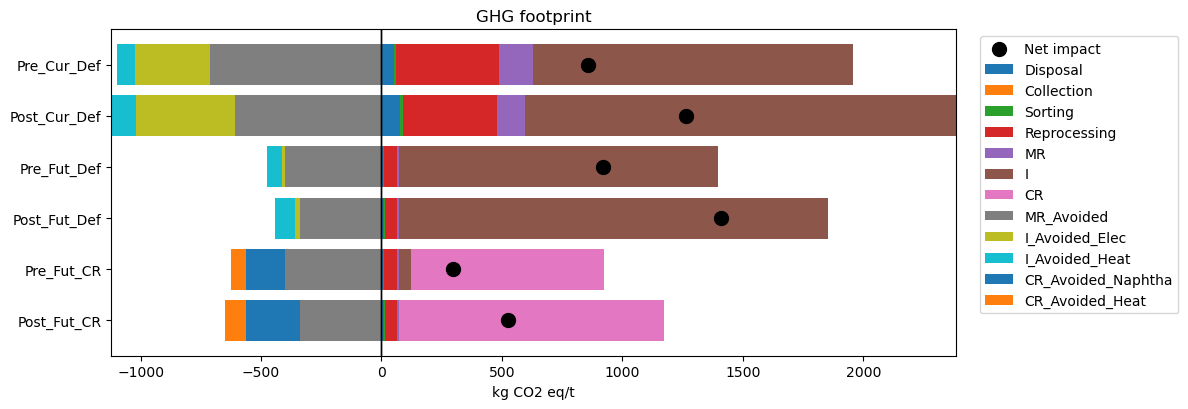

In [56]:
## Plotting env impact
process_order = [
    "Disposal",
    "Collection",
    "Sorting",
    "Reprocessing",
    "MR",
    "I",
    "CR",
    "MR_Avoided",
    "I_Avoided_Elec",
    "I_Avoided_Heat",
    "CR_Avoided_Naphtha",
    "CR_Avoided_Heat"
]

scenario_order = [
    "Post_Fut_CR",
    "Pre_Fut_CR",
    "Post_Fut_Def",
    "Pre_Fut_Def",
    "Post_Cur_Def",
    "Pre_Cur_Def"  
]


all_scenario_impacts = all_scenario_impacts.reindex(index=scenario_order)
all_scenario_impacts = all_scenario_impacts.reindex(columns=process_order)

#create figure
fig, ax = plt.subplots(figsize=(12, max(4, 0.7 * len(all_scenario_impacts))))

# Separate stacking to the right and left of zero
left_pos = pd.Series(0, index=all_scenario_impacts.index, dtype=float)
left_neg = pd.Series(0, index=all_scenario_impacts.index, dtype=float)

for col in all_scenario_impacts.columns:
    vals = all_scenario_impacts[col].astype(float)

    if (vals < 0).any():
        ax.barh(all_scenario_impacts.index, vals, left=left_neg, label=col)
        left_neg = left_neg + vals
    else:
        ax.barh(all_scenario_impacts.index, vals, left=left_pos, label=col)
        left_pos = left_pos + vals


ax.axvline(0, color="black", linewidth=1)

avoided_cols = ["MR_Avoided",
                "I_Avoided_Elec", 
                "I_Avoided_Heat",
                "CR_Avoided_Naphtha",
                "CR_Avoided_Heat"]

# total positive impacts per scenario
pos = all_scenario_impacts.clip(lower=0).sum(axis=1)

# total avoided impacts per scenario
neg = all_scenario_impacts[avoided_cols].abs().sum(axis=1)

# net impact per scenario
net_impacts = pos - neg

# Add one dot per scenario
ax.scatter(
    net_impacts,
    all_scenario_impacts.index,
    s=100,
    c="black",
    marker="o",
    zorder=10,
    label="Net impact"
)
# Zero line
ax.axvline(0, color="black", linewidth=1)

# Labels and title
ax.set_xlabel("kg CO2 eq/t")
ax.set_title("GHG footprint")

# Legend outside plot
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

#create timstamp
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
plt.savefig(f'GHG_footprint_scenarios_{timestamp}.png', dpi=300, bbox_inches='tight')
plt.show()

In [139]:
print(net_impacts)

Post_Fut_CR      420.908951
Pre_Fut_CR      1323.976217
Post_Fut_Def    1228.536594
Pre_Fut_Def     1617.902202
Post_Cur_Def    1092.255533
Pre_Cur_Def     1331.094230
dtype: float64


In [47]:
print(all_scenario_impacts)

               Disposal  Collection    Sorting  Reprocessing          MR  \
Post_Fut_CR    8.331000       1.263   3.922424     49.475417   10.340754   
Pre_Fut_CR     6.211249       1.263   1.825977     42.260480    9.489826   
Post_Fut_Def   8.331000       1.263   3.922424     49.475417   10.340754   
Pre_Fut_Def    6.211249       1.263   1.825977     42.260480    9.489826   
Post_Cur_Def  75.080000       2.564  12.039366    389.250524  133.036945   
Pre_Cur_Def   55.978583       2.564   5.604598    332.722681  122.157198   

                        I           CR  MR_Avoided  I_Avoided_Elec  \
Post_Fut_CR      0.000000  1019.936562 -387.382176        0.000000   
Pre_Fut_CR     678.511210   550.438587 -350.726742        6.607613   
Post_Fut_Def  1638.008737     0.000000 -387.382176      -16.237574   
Pre_Fut_Def   1542.990366     0.000000 -350.726742      -15.325313   
Post_Cur_Def  1646.636361     0.000000 -690.245736     -382.009226   
Pre_Cur_Def   1551.055840     0.000000 -625.447

In [16]:
# read excel 
net_impacts_sens = pd.read_excel("net_impacts_sens.xlsx")

# check if excel is read as expected
print(net_impacts_sens[["scenario", "parameter", "param_pct_change", "net_pct_change"]].head())

              scenario                          parameter  param_pct_change  \
0  Pre-sorting current               fraction plastic msw               -67   
1  Pre-sorting current               fraction plastic msw                 0   
2  Pre-sorting current               fraction plastic msw                48   
3  Pre-sorting current  substitution ratio MR PET bottles               -94   
4  Pre-sorting current  substitution ratio MR PET bottles                 0   

   net_pct_change  
0           -15.2  
1             0.0  
2             7.1  
3             6.6  
4             0.0  


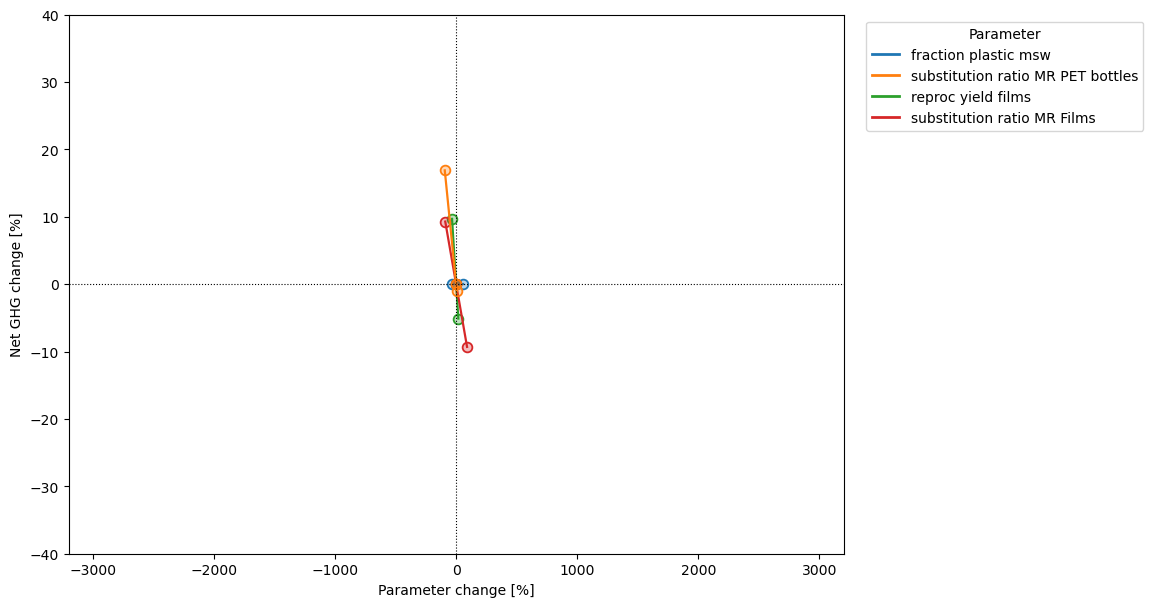

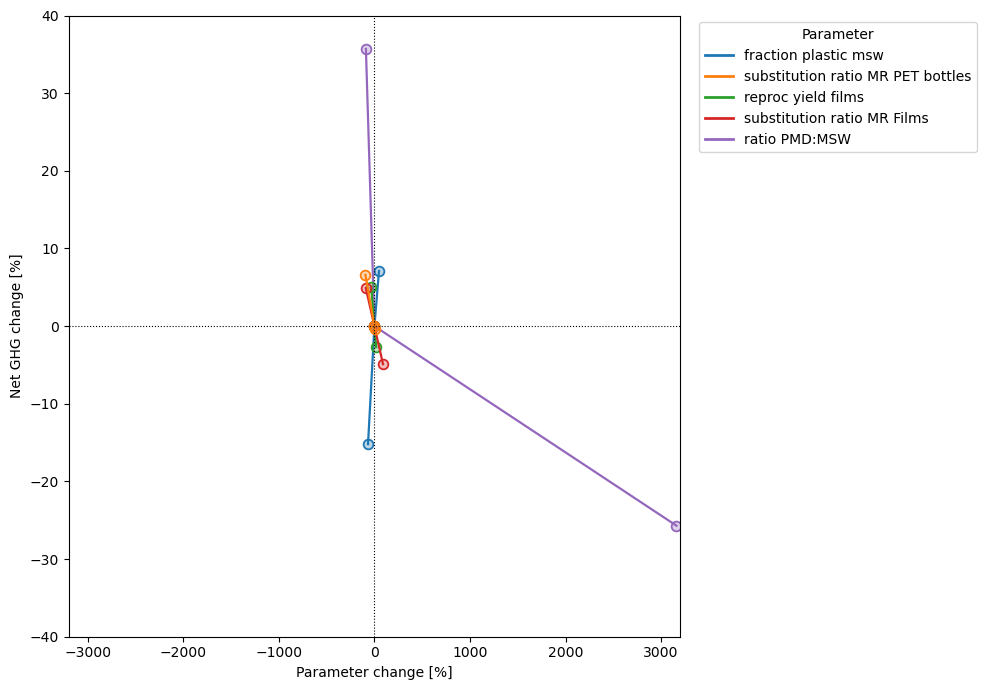

In [23]:


from matplotlib import colors as mcolors
from matplotlib.lines import Line2D

# split scenarios

scenario_styles = {
    "Pre-sorting current": {"linestyle": "-", "marker": "o"},
    "Post-sorting current": {"linestyle": "-", "marker": "o"}
}

parameters = net_impacts_sens["parameter"].unique()
colors = plt.cm.tab10.colors
parameter_colors = {param: colors[i % len(colors)] for i, param in enumerate(parameters)}

for scenario, scenario_data in net_impacts_sens.groupby("scenario"):
    fig, ax = plt.subplots(figsize=(10, 7))

    style = scenario_styles[scenario]

    for parameter, group in scenario_data.groupby("parameter"):
        group = group.sort_values("param_pct_change")

        color = parameter_colors[parameter]
        marker_fill = mcolors.to_rgba(color, alpha=0.3)

        ax.plot(
            group["param_pct_change"],
            group["net_pct_change"],
            color=color,
            linestyle=style["linestyle"],
            linewidth=1.6,
            marker=style["marker"],
            markersize=7,
            markerfacecolor=marker_fill,
            markeredgecolor=color,
            markeredgewidth=1.3,
            label=parameter
        )

    ax.set_xlabel("Parameter change [%]")
    ax.set_ylabel("Net GHG change [%]")
    ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
    ax.axvline(0, color="black", linewidth=0.8, linestyle=":")

    ax.set_xlim(-3200, 3200)
    ax.set_ylim(-40, 40)

    parameter_handles = [
        Line2D([0], [0], color=parameter_colors[param], lw=2, label=param)
        for param in scenario_data["parameter"].unique()
    ]

    ax.legend(handles=parameter_handles, title="Parameter", loc="upper left", bbox_to_anchor=(1.02, 1))
    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    plt.savefig(f'sens_anal_{scenario}_{timestamp}.png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

# row = df.loc[df["Parameter"] == "Yield"].iloc[0]

# sensitivity_data = pd.DataFrame({
#     "Parameter_Value": ["min", "avg", "max"],
#     "Net_Impact": [row["min"], row["avg"], row["max"]],
# })


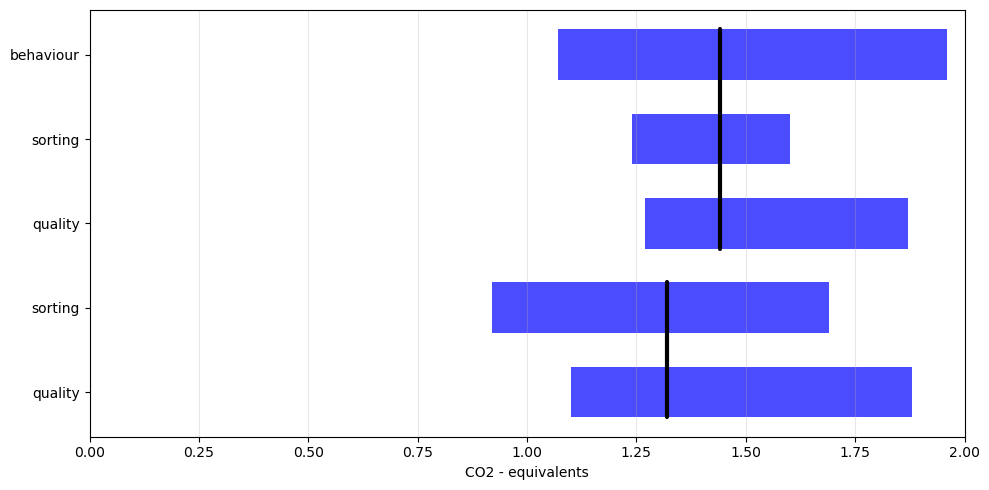

In [38]:
# carbon footprint sensitivity


# Read the excel file
# Expected columns: scenario, parameter, carbon_footprint
df = pd.read_excel('net_impacts_sens_grouped.xlsx')

# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Get unique scenarios
scenarios = df['scenario'].unique()
parameters = df['parameter'].unique()

# Define markers and colours
param_colors = {
    'current': 'black',
    'behaviour': 'blue',
    'sorting': 'blue',
    'quality': 'blue'
}


bar_height = 0.6  # height of each parameter bar

# Build a list of y-positions and labels for the y-axis
y_ticks = []
y_labels = []

current_y = 0
for scenario in scenarios:
    scenario_data = df[df['scenario'] == scenario]
        # Get baseline (current) value for this scenario
    current_data = scenario_data[scenario_data['parameter'] == 'current']['carbon_footprint']
    cf_current = current_data.iloc[0] if len(current_data) > 0 else None
    
    # Then: plot other parameters as horizontal bars (ranges)
    for param in parameters:
        if param == 'current':
            continue  # skip, already plotted as line
        
        param_data = scenario_data[scenario_data['parameter'] == param]['carbon_footprint']
        if len(param_data) == 0:
            continue
        
        cf_min = param_data.min()
        cf_max = param_data.max()
        cf_range = cf_max - cf_min
        
        ax.barh(
            current_y,
            cf_range,
            left=cf_min,
            height=bar_height,
            color=param_colors.get(param, 'gray'),
            alpha=0.7
        )
        
        y_ticks.append(current_y)
        y_labels.append(f"{param}")
        current_y += 1

    # After plotting bars for this scenario, add vertical baseline line
    # spanning the rows of this scenario
    if cf_current is not None:
        # Determine y-range covered by this scenario's bars
        if current_y > 0:
            # Find first and last y for this scenario
            # We can compute how many bars we added for this scenario:
            n_bars_scenario = sum(
                1 for param in bar_parameters
                if len(scenario_data[scenario_data['parameter'] == param]) > 0
            )
            if n_bars_scenario > 0:
                y_start = current_y - n_bars_scenario
                y_end = current_y - 0.0
                # Draw vertical line through this scenario's block
                ax.plot(
                    [cf_current, cf_current],
                    [y_start - 0.3, y_end - 0.7],
                    color=param_colors.get('current', 'black'),
                    linewidth=3,
                    solid_capstyle='round',
                    label='current (baseline)'
                )


# Set y-axis to show scenario + parameter labels
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)
ax.invert_yaxis()

# Labels and title
ax.set_xlabel('CO2 - equivalents')
ax.set_xlim(0,2)

# Add grid for readability
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
# plt.savefig('carbon_footprint_ranges_baseline.png', dpi=300)
plt.show()

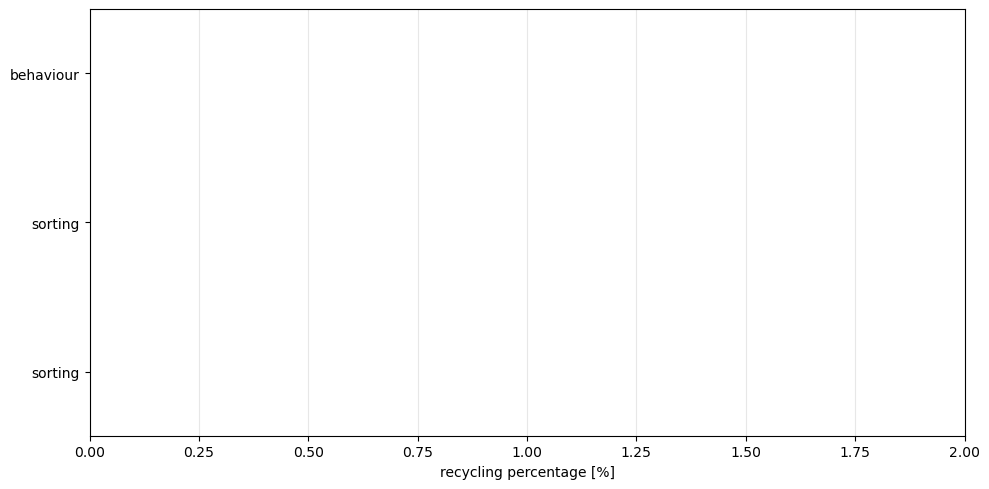

In [ ]:
# recycling sensitivity


# Read the CSV file
# Expected columns: scenario, parameter, recycling_percentage
df = pd.read_excel('net_impacts_sens_recycling.xlsx')


# Create figure and axis
fig, ax = plt.subplots(figsize=(10, 5))

# Get unique scenarios
scenarios = df['scenario'].unique()
parameters = df['parameter'].unique()

# Define markers and colours
param_colors = {
    'current': 'black',
    'behaviour': 'blue',
    'sorting': 'blue',
    'quality': 'blue'
}


bar_height = 0.6  # height of each parameter bar

# Build a list of y-positions and labels for the y-axis
y_ticks = []
y_labels = []

current_y = 0
for scenario in scenarios:
    scenario_data = df[df['scenario'] == scenario]
        # Get baseline (current) value for this scenario
    current_data = scenario_data[scenario_data['parameter'] == 'current']['recycling_percentage']
    cf_current = current_data.iloc[0] if len(current_data) > 0 else None
    
    # Then: plot other parameters as horizontal bars (ranges)
    for param in parameters:
        if param == 'current':
            continue  # skip, already plotted as line

        param_data = scenario_data[scenario_data['parameter'] == param]['recycling_percentage']
        if len(param_data) == 0:
            continue
        
        cf_min = param_data.min()
        cf_max = param_data.max()
        cf_range = cf_max - cf_min
        
        ax.barh(
            current_y,
            cf_range,
            left=cf_min,
            height=bar_height,
            color=param_colors.get(param, 'gray'),
            alpha=0.7
        )
        
        y_ticks.append(current_y)
        y_labels.append(f"{param}")
        current_y += 1

    # After plotting bars for this scenario, add vertical baseline line
    # spanning the rows of this scenario
    if cf_current is not None:
        # Determine y-range covered by this scenario's bars
        if current_y > 0:
            # Find first and last y for this scenario
            # We can compute how many bars we added for this scenario:
            n_bars_scenario = sum(
                1 for param in bar_parameters
                if len(scenario_data[scenario_data['parameter'] == param]) > 0
            )
            if n_bars_scenario > 0:
                y_start = current_y - n_bars_scenario
                y_end = current_y - 0.0
                # Draw vertical line through this scenario's block
                ax.plot(
                    [cf_current, cf_current],
                    [y_start - 0.3, y_end - 0.7],
                    color=param_colors.get('current', 'black'),
                    linewidth=3,
                    solid_capstyle='round',
                    label='current (baseline)'
                )


# Set y-axis to show scenario + parameter labels
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)
ax.invert_yaxis()

# Labels and title
ax.set_xlabel('recycling percentage [%]')
ax.set_xlim(0,2)

# Add grid for readability
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
# plt.savefig('carbon_footprint_ranges_baseline.png', dpi=300)
plt.show()

In [43]:
cf_min

np.float64(18.2)